# PDCAN fixed-epoch ablation experiments

This notebook uses the selected PDCAN as the reference model, so all non-AR ablations are based on the no-autoregressive-feedback architecture.

In [1]:
pip install torch numpy pandas matplotlib openpyxl ipython notebook ipykernel

Looking in indexes: https://mirrors.aliyun.com/pypi/simple

[notice] A new release of pip is available: 24.2 -> 26.1.2
[notice] To update, run: python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# -*- coding: utf-8 -*-
"""
Fixed-epoch PDCAN ablation experiments using the selected PDCAN architecture as the reference model.

数据：
- 训练+验证全集：./data.csv
- 固定测试集：./test.csv

功能：
1. 使用前期验证集筛选得到的最优超参数；
2. 使用验证阶段得到的 mean_best_epoch 作为固定训练轮次；
3. 在 ./data.csv 全量训练数据上重新训练；
4. 每个 epoch 在 ./test.csv 上仅做监控评估，输出 loss、Sval、MAE、RMSE、R2、ME；
5. 不使用测试集早停，不根据测试集选择最佳 epoch；
6. 训练到固定轮次后，使用最后一个 epoch 的模型在测试集上报告最终结果；
7. 保存五个 PDCAN 消融变体的测试结果、训练曲线、逐预测步长误差和预测值；
8. 针对 PDCAN 主模型输出 type=1/2/3 分类型指标、代表性样本轨迹图、mPSI 散点图和残差分布图；
9. 输出 PDCAN 消融模型的整体指标、相对 PDCAN 的差值和分类型指标。
"""

import os
import json
import math
import random
import copy
import warnings
from dataclasses import dataclass
from typing import Dict, List, Tuple, Any

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except Exception:
    def display(x):
        print(x)

warnings.filterwarnings("ignore")

In [3]:
# =========================
# 1. Global configuration for PDCAN ablation experiments
# =========================
TRAIN_PATH = "../data/data.csv"
TEST_PATH = "../data/test.csv"
OUTPUT_DIR = "../results/ablation"
os.makedirs(OUTPUT_DIR, exist_ok=True)

SEED = 42
FIXED_ABLATION_EPOCHS = 50
NUM_WORKERS = 0
GRAD_CLIP_NORM = 1.0
USE_AMP = False
PRINT_EVERY = 1

# The test set is used only for monitoring and final fixed-epoch reporting.
# It is not used for early stopping or model selection.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

SVAL_WEIGHTS = {
    "mPSI": 0.40,
    "HR": 0.20,
    "Tskin": 0.20,
    "Tcore": 0.20,
}

USE_DATASET_TMAX_HRMAX = True


def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


seed_everything(SEED)


# Change this list if you only want to rerun a subset after interruption.
MODELS_TO_RUN = None  # None means run all variants in ABLATION_ORDER.


Using device: cuda
GPU: NVIDIA GeForce RTX 3090


In [4]:
# =========================
# 2. 数据读取与标准化
# =========================
@dataclass
class RawData:
    x_static: np.ndarray        # [N, 5]
    x_hist: np.ndarray          # [N, 30, 7]
    u_ctrl: np.ndarray          # [N, 15, 5]
    y_seq: np.ndarray           # [N, 15, 3], [HR,Tskin,Tcore]
    y_mpsi: np.ndarray          # [N, 1]
    init_phys: np.ndarray       # [N, 2], [HR_t,Tskin_t]
    meta: np.ndarray            # [N, 5], [T0,HR0,Tmax_col,HRmax_col,age]
    type_label: np.ndarray      # [N, 1], test intervention type: 1/2/3; train may be NaN
    sample_id: np.ndarray       # [N, 1], stable 0-based id after filtering, aligned with model arrays
    source_row: np.ndarray      # [N, 1], original CSV/Excel row number assuming header is row 1
    df: pd.DataFrame


def load_csv(path: str, name: str = "data") -> RawData:
    """
    读取训练集或测试集。

    前 340 列保持原始模型输入/标签格式：
    1-5 静态特征；6-215 历史 30×7；216-335 未来 15×8；
    336-339 meta；340 mPSI。

    如果文件存在第 341 列，则将其作为测试集 type 标签：
    type=1 仅休息干预；type=2 休息+环境条件变化；type=3 降低工作强度。
    该列不会进入模型训练，只用于测试集分组评价和绘图。
    """
    if not os.path.exists(path):
        raise FileNotFoundError(f"找不到{name}文件：{path}")
    df = pd.read_csv(path)
    # 保留原始行定位信息。source_row 对应 Excel/CSV 中的实际行号：表头为第1行，第一条数据为第2行。
    original_source_row = (np.arange(len(df), dtype=np.int64) + 2).reshape(-1, 1)
    if df.shape[1] < 340:
        raise ValueError(f"{name}至少应有 340 列，但当前只有 {df.shape[1]} 列。")

    arr = df.iloc[:, :340].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=np.float32)

    # 第 341 列为测试集干预类型，仅用于评估，不进入模型输入。
    if df.shape[1] >= 341:
        type_label = pd.to_numeric(df.iloc[:, 340], errors="coerce").to_numpy(dtype=np.float32).reshape(-1, 1)
        print(f"{name}: 检测到 type 列：{df.columns[340]}")
    else:
        type_label = np.full((len(df), 1), np.nan, dtype=np.float32)
        print(f"{name}: 未检测到第341列 type，分类型测试分析将跳过。")

    x_static = arr[:, 0:5]
    x_hist = arr[:, 5:215].reshape(-1, 30, 7)
    u_all = arr[:, 215:335].reshape(-1, 15, 8)

    u_ctrl = u_all[:, :, 0:5]
    y_seq = u_all[:, :, [7, 6, 5]]  # 输出顺序：HR、Tskin、Tcore
    init_phys = x_hist[:, -1, [6, 5]]  # HR_t、Tskin_t

    T0 = arr[:, 335:336]
    HR0 = arr[:, 336:337]
    Tmax_col = arr[:, 337:338]
    HRmax_col = arr[:, 338:339]
    age = x_static[:, 1:2]
    meta = np.concatenate([T0, HR0, Tmax_col, HRmax_col, age], axis=1)
    y_mpsi = arr[:, 339:340]

    valid = np.isfinite(y_seq).all(axis=(1, 2)) & np.isfinite(y_mpsi).all(axis=1)
    if valid.sum() < len(valid):
        print(f"{name}: 删除 {len(valid) - valid.sum()} 行关键标签缺失的数据。")
        x_static = x_static[valid]
        x_hist = x_hist[valid]
        u_ctrl = u_ctrl[valid]
        y_seq = y_seq[valid]
        y_mpsi = y_mpsi[valid]
        init_phys = init_phys[valid]
        meta = meta[valid]
        type_label = type_label[valid]
        original_source_row = original_source_row[valid]
        df = df.loc[valid].reset_index(drop=True)

    print(f"{name}读取完成：")
    print("  x_static:", x_static.shape)
    print("  x_hist  :", x_hist.shape)
    print("  u_ctrl  :", u_ctrl.shape)
    print("  y_seq   :", y_seq.shape, "[HR, Tskin, Tcore]")
    print("  y_mPSI  :", y_mpsi.shape)
    if np.isfinite(type_label).any():
        print("  type    :", pd.Series(type_label.reshape(-1)).value_counts(dropna=False).sort_index().to_dict())
    sample_id = np.arange(len(y_mpsi), dtype=np.int64).reshape(-1, 1)
    return RawData(x_static, x_hist, u_ctrl, y_seq, y_mpsi, init_phys, meta, type_label, sample_id, original_source_row, df)


class NanStandardizer:
    def __init__(self, eps: float = 1e-8):
        self.eps = eps
        self.mean_ = None
        self.scale_ = None

    def fit(self, x: np.ndarray):
        x = np.asarray(x, dtype=np.float32)
        self.mean_ = np.nanmean(x, axis=0).astype(np.float32)
        self.scale_ = np.nanstd(x, axis=0).astype(np.float32)
        self.scale_ = np.where(self.scale_ < self.eps, 1.0, self.scale_).astype(np.float32)
        return self

    def transform(self, x: np.ndarray) -> np.ndarray:
        z = (np.asarray(x, dtype=np.float32) - self.mean_) / self.scale_
        return np.nan_to_num(z, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)

    def inverse_transform(self, z: np.ndarray) -> np.ndarray:
        return (np.asarray(z, dtype=np.float32) * self.scale_ + self.mean_).astype(np.float32)


@dataclass
class Scalers:
    static: NanStandardizer
    hist: NanStandardizer
    ctrl: NanStandardizer
    y_phys: NanStandardizer
    y_mpsi: NanStandardizer


def fit_scalers(train_raw: RawData) -> Scalers:
    return Scalers(
        static=NanStandardizer().fit(train_raw.x_static),
        hist=NanStandardizer().fit(train_raw.x_hist.reshape(-1, 7)),
        ctrl=NanStandardizer().fit(train_raw.u_ctrl.reshape(-1, 5)),
        y_phys=NanStandardizer().fit(train_raw.y_seq.reshape(-1, 3)),
        y_mpsi=NanStandardizer().fit(train_raw.y_mpsi),
    )


def transform_raw(raw: RawData, scalers: Scalers) -> Dict[str, np.ndarray]:
    x_static = scalers.static.transform(raw.x_static)
    x_hist = scalers.hist.transform(raw.x_hist.reshape(-1, 7)).reshape(-1, 30, 7)
    u_ctrl = scalers.ctrl.transform(raw.u_ctrl.reshape(-1, 5)).reshape(-1, 15, 5)
    y_seq = scalers.y_phys.transform(raw.y_seq.reshape(-1, 3)).reshape(-1, 15, 3)
    y_mpsi = scalers.y_mpsi.transform(raw.y_mpsi)

    init_raw = raw.init_phys.copy()
    y_mean = scalers.y_phys.mean_
    y_std = scalers.y_phys.scale_
    init_phys = np.empty_like(init_raw, dtype=np.float32)
    init_phys[:, 0] = (init_raw[:, 0] - y_mean[0]) / y_std[0]
    init_phys[:, 1] = (init_raw[:, 1] - y_mean[1]) / y_std[1]
    init_phys = np.nan_to_num(init_phys, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)

    return {
        "x_static": x_static,
        "x_hist": x_hist,
        "u_ctrl": u_ctrl,
        "y_seq": y_seq,
        "y_mpsi": y_mpsi,
        "init_phys": init_phys,
        "meta": np.nan_to_num(raw.meta, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32),
        # type_label、sample_id、source_row 只用于测试集分组分析和绘图，不参与模型计算。
        "type_label": raw.type_label.astype(np.float32),
        "sample_id": raw.sample_id.astype(np.float32),
        "source_row": raw.source_row.astype(np.float32),
    }


class PhysioDataset(Dataset):
    def __init__(self, data_dict: Dict[str, np.ndarray]):
        self.data = {k: torch.tensor(v, dtype=torch.float32) for k, v in data_dict.items()}
        self.n = len(next(iter(self.data.values())))

    def __len__(self):
        return self.n

    def __getitem__(self, i):
        return {k: v[i] for k, v in self.data.items()}


def make_loader(data_dict: Dict[str, np.ndarray], batch_size: int, shuffle: bool) -> DataLoader:
    return DataLoader(
        PhysioDataset(data_dict),
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda"),
        drop_last=False,
    )

In [5]:
# =========================
# 3. 通用模块
# =========================
def make_activation(name: str):
    name = name.lower()
    if name == "gelu":
        return nn.GELU()
    if name == "silu":
        return nn.SiLU()
    if name == "relu":
        return nn.ReLU()
    raise ValueError(f"Unknown activation: {name}")


class MLP(nn.Module):
    def __init__(self, in_dim: int, hidden_dims: Tuple[int, ...], out_dim: int = None,
                 dropout: float = 0.1, activation: str = "gelu", layer_norm: bool = True):
        super().__init__()
        dims = [in_dim] + list(hidden_dims)
        if out_dim is not None:
            dims.append(out_dim)
        layers = []
        for i in range(len(dims) - 1):
            layers.append(nn.Linear(dims[i], dims[i + 1]))
            if layer_norm:
                layers.append(nn.LayerNorm(dims[i + 1]))
            layers.append(make_activation(activation))
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


class FormulaMPSIMixin:
    def formula_mpsi_norm(self, final_y_norm, meta):
        final_raw = final_y_norm * self.y_phys_std + self.y_phys_mean
        HR_pred = final_raw[:, 0:1]
        Tcore_pred = final_raw[:, 2:3]

        T0 = meta[:, 0:1]
        HR0 = meta[:, 1:2]
        Tmax_col = meta[:, 2:3]
        HRmax_col = meta[:, 3:4]
        age = meta[:, 4:5]

        Tmax_formula = torch.full_like(T0, 38.5)
        HRmax_formula = 180.0 - 0.65 * age

        if self.use_dataset_tmax_hrmax:
            valid_tmax = torch.isfinite(Tmax_col) & (Tmax_col > T0 + 1e-3)
            valid_hrmax = torch.isfinite(HRmax_col) & (HRmax_col > HR0 + 1e-3)
            Tmax = torch.where(valid_tmax, Tmax_col, Tmax_formula)
            HRmax = torch.where(valid_hrmax, HRmax_col, HRmax_formula)
        else:
            Tmax, HRmax = Tmax_formula, HRmax_formula

        denom_t = torch.clamp(Tmax - T0, min=1e-3)
        denom_hr = torch.clamp(HRmax - HR0, min=1e-3)
        mpsi_raw = 5.0 * (Tcore_pred - T0) / denom_t + 5.0 * (HR_pred - HR0) / denom_hr
        return (mpsi_raw - self.mpsi_mean) / self.mpsi_std

    def register_scaler_buffers(self, y_phys_mean, y_phys_std, mpsi_mean, mpsi_std):
        self.register_buffer("y_phys_mean", torch.tensor(y_phys_mean.reshape(1, 3), dtype=torch.float32))
        self.register_buffer("y_phys_std", torch.tensor(y_phys_std.reshape(1, 3), dtype=torch.float32))
        self.register_buffer("mpsi_mean", torch.tensor([[mpsi_mean]], dtype=torch.float32))
        self.register_buffer("mpsi_std", torch.tensor([[mpsi_std]], dtype=torch.float32))


class TemporalBlock(nn.Module):
    def __init__(self, in_ch: int, out_ch: int, kernel_size: int, dilation: int,
                 dropout: float = 0.1, activation: str = "gelu"):
        super().__init__()
        padding = dilation * (kernel_size - 1) // 2
        self.conv1 = nn.Conv1d(in_ch, out_ch, kernel_size, padding=padding, dilation=dilation)
        self.norm1 = nn.BatchNorm1d(out_ch)
        self.conv2 = nn.Conv1d(out_ch, out_ch, kernel_size, padding=padding, dilation=dilation)
        self.norm2 = nn.BatchNorm1d(out_ch)
        self.act = make_activation(activation)
        self.dropout = nn.Dropout(dropout)
        self.resample = nn.Conv1d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x):
        y = self.conv1(x)
        y = self.norm1(y)
        y = self.act(y)
        y = self.dropout(y)
        y = self.conv2(y)
        y = self.norm2(y)
        y = self.dropout(y)
        return self.act(y + self.resample(x))


class TCN(nn.Module):
    def __init__(self, in_dim: int, channels: Tuple[int, ...], kernel_size: int = 3,
                 dropout: float = 0.1, activation: str = "gelu"):
        super().__init__()
        layers = []
        prev = in_dim
        for i, ch in enumerate(channels):
            layers.append(TemporalBlock(prev, ch, kernel_size, dilation=2 ** i,
                                        dropout=dropout, activation=activation))
            prev = ch
        self.net = nn.Sequential(*layers)
        self.out_dim = prev

    def forward(self, x):
        y = x.transpose(1, 2)
        y = self.net(y)
        return y.transpose(1, 2)


class StackedVariableGRU(nn.Module):
    def __init__(self, input_size: int, hidden_dims: Tuple[int, ...], dropout: float = 0.1):
        super().__init__()
        self.hidden_dims = tuple(int(h) for h in hidden_dims)
        self.layers = nn.ModuleList()
        self.dropout = nn.Dropout(dropout) if dropout > 0 else nn.Identity()
        prev_dim = input_size
        for h in self.hidden_dims:
            self.layers.append(nn.GRU(input_size=prev_dim, hidden_size=h, num_layers=1, batch_first=True))
            prev_dim = h

    def forward(self, x):
        out = x
        last_h = None
        for i, gru in enumerate(self.layers):
            out, h = gru(out)
            last_h = h[-1]
            if i < len(self.layers) - 1:
                out = self.dropout(out)
        return out, last_h


class StackedVariableLSTM(nn.Module):
    def __init__(self, input_size: int, hidden_dims: Tuple[int, ...], dropout: float = 0.1):
        super().__init__()
        self.hidden_dims = tuple(int(h) for h in hidden_dims)
        self.layers = nn.ModuleList()
        self.dropout = nn.Dropout(dropout) if dropout > 0 else nn.Identity()
        prev_dim = input_size
        for h in self.hidden_dims:
            self.layers.append(nn.LSTM(input_size=prev_dim, hidden_size=h, num_layers=1, batch_first=True))
            prev_dim = h

    def forward(self, x):
        out = x
        last_h, last_c = None, None
        for i, lstm in enumerate(self.layers):
            out, (h, c) = lstm(out)
            last_h, last_c = h[-1], c[-1]
            if i < len(self.layers) - 1:
                out = self.dropout(out)
        return out, last_h, last_c


def build_encoder_input(x_static, x_hist):
    B, T, _ = x_hist.shape
    static_seq = x_hist.new_zeros(B, T, x_static.size(-1))
    static_seq[:, 0, :] = x_static
    return torch.cat([x_hist, static_seq], dim=-1)

In [6]:
# =========================
# 6. 损失、评价指标、Sval、ME
# =========================
def to_device(batch: Dict[str, torch.Tensor], device=DEVICE):
    return {k: v.to(device, non_blocking=True) for k, v in batch.items()}


def compute_loss(outputs: Dict[str, torch.Tensor], batch: Dict[str, torch.Tensor], hp: Dict[str, Any]):
    pred_seq = outputs["phys_seq"]
    true_seq = batch["y_seq"]
    pred_mpsi = outputs["mpsi"]
    true_mpsi = batch["y_mpsi"]

    mse_seq = (pred_seq - true_seq) ** 2
    phys_loss = (
        hp["alpha_hr"] * mse_seq[:, :, 0].mean() +
        hp["alpha_tskin"] * mse_seq[:, :, 1].mean() +
        hp["alpha_tcore"] * mse_seq[:, :, 2].mean()
    )
    mpsi_loss = F.mse_loss(pred_mpsi, true_mpsi)

    if pred_seq.size(1) >= 3:
        d2 = pred_seq[:, 2:, :] - 2 * pred_seq[:, 1:-1, :] + pred_seq[:, :-2, :]
        smooth_loss = (d2 ** 2).mean()
    else:
        smooth_loss = torch.zeros((), device=pred_seq.device)

    total = hp["lambda_phys"] * phys_loss + hp["lambda_mpsi"] * mpsi_loss + hp["lambda_smooth"] * smooth_loss
    return total, {
        "loss_total": float(total.detach().cpu()),
        "loss_phys": float(phys_loss.detach().cpu()),
        "loss_mpsi": float(mpsi_loss.detach().cpu()),
        "loss_smooth": float(smooth_loss.detach().cpu()),
    }


def inverse_phys(z: np.ndarray, scaler: NanStandardizer) -> np.ndarray:
    return scaler.inverse_transform(z.reshape(-1, 3)).reshape(z.shape)


def inverse_mpsi(z: np.ndarray, scaler: NanStandardizer) -> np.ndarray:
    return scaler.inverse_transform(z.reshape(-1, 1)).reshape(-1, 1)


def mae_rmse_r2_me(y_true: np.ndarray, y_pred: np.ndarray) -> Tuple[float, float, float, float]:
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true = y_true[mask]
    y_pred = y_pred[mask]
    err = y_pred - y_true
    mae = float(np.mean(np.abs(err)))
    rmse = float(np.sqrt(np.mean(err ** 2)))
    me = float(np.mean(err))
    ss_res = float(np.sum((y_true - y_pred) ** 2))
    ss_tot = float(np.sum((y_true - np.mean(y_true)) ** 2))
    r2 = float(1.0 - ss_res / ss_tot) if ss_tot > 1e-12 else float("nan")
    return mae, rmse, r2, me


def compute_raw_metrics(pred_seq_norm: np.ndarray, true_seq_norm: np.ndarray,
                        pred_mpsi_norm: np.ndarray, true_mpsi_norm: np.ndarray,
                        scalers: Scalers) -> Dict[str, float]:
    pred_seq = inverse_phys(pred_seq_norm, scalers.y_phys)
    true_seq = inverse_phys(true_seq_norm, scalers.y_phys)
    pred_mpsi = inverse_mpsi(pred_mpsi_norm, scalers.y_mpsi)
    true_mpsi = inverse_mpsi(true_mpsi_norm, scalers.y_mpsi)

    metrics = {}
    for j, name in enumerate(["HR", "Tskin", "Tcore"]):
        mae, rmse, r2, me = mae_rmse_r2_me(true_seq[:, :, j], pred_seq[:, :, j])
        metrics[f"MAE_{name}"] = mae
        metrics[f"RMSE_{name}"] = rmse
        metrics[f"R2_{name}"] = r2
        metrics[f"ME_{name}"] = me

    mae, rmse, r2, me = mae_rmse_r2_me(true_mpsi, pred_mpsi)
    metrics["MAE_mPSI"] = mae
    metrics["RMSE_mPSI"] = rmse
    metrics["R2_mPSI"] = r2
    metrics["ME_mPSI"] = me

    std_hr, std_tskin, std_tcore = scalers.y_phys.scale_.tolist()
    std_mpsi = float(scalers.y_mpsi.scale_[0])
    metrics["Sval"] = (
        SVAL_WEIGHTS["mPSI"] * metrics["MAE_mPSI"] / max(std_mpsi, 1e-8) +
        SVAL_WEIGHTS["HR"] * metrics["MAE_HR"] / max(std_hr, 1e-8) +
        SVAL_WEIGHTS["Tskin"] * metrics["MAE_Tskin"] / max(std_tskin, 1e-8) +
        SVAL_WEIGHTS["Tcore"] * metrics["MAE_Tcore"] / max(std_tcore, 1e-8)
    )
    return metrics


def compute_step_metrics(pred_seq_norm: np.ndarray, true_seq_norm: np.ndarray, scalers: Scalers) -> pd.DataFrame:
    pred_seq = inverse_phys(pred_seq_norm, scalers.y_phys)
    true_seq = inverse_phys(true_seq_norm, scalers.y_phys)
    rows = []
    for k in range(pred_seq.shape[1]):
        row = {"minute": k + 1}
        for j, name in enumerate(["HR", "Tskin", "Tcore"]):
            mae, rmse, r2, me = mae_rmse_r2_me(true_seq[:, k, j], pred_seq[:, k, j])
            row[f"MAE_{name}"] = mae
            row[f"RMSE_{name}"] = rmse
            row[f"R2_{name}"] = r2
            row[f"ME_{name}"] = me
        rows.append(row)
    return pd.DataFrame(rows)


def collect_predictions(pred_seq_norm: np.ndarray, true_seq_norm: np.ndarray,
                        pred_mpsi_norm: np.ndarray, true_mpsi_norm: np.ndarray,
                        scalers: Scalers, type_labels: np.ndarray = None,
                        sample_ids: np.ndarray = None, source_rows: np.ndarray = None) -> Tuple[pd.DataFrame, pd.DataFrame]:
    """
    将模型输出反标准化，并保存为 long-format DataFrame。
    关键修正：不再假设 sample=数组顺序一定等于原始 test.csv 行号，而是显式使用 evaluate 中从 DataLoader 同批次带出的
    sample_id/source_row/type_label，保证预测值、真实值、type 和原始行号一一对应。
    """
    pred_seq = inverse_phys(pred_seq_norm, scalers.y_phys)
    true_seq = inverse_phys(true_seq_norm, scalers.y_phys)
    pred_mpsi = inverse_mpsi(pred_mpsi_norm, scalers.y_mpsi)
    true_mpsi = inverse_mpsi(true_mpsi_norm, scalers.y_mpsi)

    n = pred_seq.shape[0]
    if type_labels is None:
        type_arr = np.full(n, np.nan, dtype=np.float32)
    else:
        type_arr = np.asarray(type_labels).reshape(-1).astype(np.float32)
    if sample_ids is None:
        sample_arr = np.arange(n, dtype=np.int64)
    else:
        sample_arr = np.asarray(sample_ids).reshape(-1).astype(np.int64)
    if source_rows is None:
        source_row_arr = np.arange(n, dtype=np.int64) + 2
    else:
        source_row_arr = np.asarray(source_rows).reshape(-1).astype(np.int64)

    rows = []
    for i in range(n):
        type_i = type_arr[i] if i < len(type_arr) else np.nan
        sample_i = int(sample_arr[i]) if i < len(sample_arr) else int(i)
        source_row_i = int(source_row_arr[i]) if i < len(source_row_arr) else int(i + 2)
        for k in range(pred_seq.shape[1]):
            rows.append({
                "array_index": i,
                "sample_id": sample_i,
                "source_row": source_row_i,
                "type": type_i,
                "minute": k + 1,
                "HR_true": true_seq[i, k, 0],
                "HR_pred": pred_seq[i, k, 0],
                "Tskin_true": true_seq[i, k, 1],
                "Tskin_pred": pred_seq[i, k, 1],
                "Tcore_true": true_seq[i, k, 2],
                "Tcore_pred": pred_seq[i, k, 2],
            })
    traj_df = pd.DataFrame(rows)
    mpsi_df = pd.DataFrame({
        "array_index": np.arange(n),
        "sample_id": sample_arr,
        "source_row": source_row_arr,
        "type": type_arr,
        "mPSI_true": true_mpsi.reshape(-1),
        "mPSI_pred": pred_mpsi.reshape(-1),
        "mPSI_error_pred_minus_true": (pred_mpsi - true_mpsi).reshape(-1),
    })
    return traj_df, mpsi_df


def compute_raw_metrics_from_raw_arrays(pred_seq: np.ndarray, true_seq: np.ndarray,
                                        pred_mpsi: np.ndarray, true_mpsi: np.ndarray) -> Dict[str, float]:
    metrics = {}
    for j, name in enumerate(["HR", "Tskin", "Tcore"]):
        mae, rmse, r2, me = mae_rmse_r2_me(true_seq[:, :, j], pred_seq[:, :, j])
        metrics[f"MAE_{name}"] = mae
        metrics[f"RMSE_{name}"] = rmse
        metrics[f"R2_{name}"] = r2
        metrics[f"ME_{name}"] = me
    mae, rmse, r2, me = mae_rmse_r2_me(true_mpsi, pred_mpsi)
    metrics["MAE_mPSI"] = mae
    metrics["RMSE_mPSI"] = rmse
    metrics["R2_mPSI"] = r2
    metrics["ME_mPSI"] = me
    return metrics


def compute_type_metrics(pred_seq_norm: np.ndarray, true_seq_norm: np.ndarray,
                         pred_mpsi_norm: np.ndarray, true_mpsi_norm: np.ndarray,
                         scalers: Scalers, type_labels: np.ndarray) -> pd.DataFrame:
    """针对测试集 type=1/2/3 分别计算 HR、Tskin、Tcore、mPSI 的 MAE/RMSE/R2/ME。"""
    type_arr = np.asarray(type_labels).reshape(-1)
    pred_seq = inverse_phys(pred_seq_norm, scalers.y_phys)
    true_seq = inverse_phys(true_seq_norm, scalers.y_phys)
    pred_mpsi = inverse_mpsi(pred_mpsi_norm, scalers.y_mpsi)
    true_mpsi = inverse_mpsi(true_mpsi_norm, scalers.y_mpsi)

    rows = []
    for t in [1, 2, 3]:
        mask = np.isfinite(type_arr) & (type_arr.astype(float) == float(t))
        if mask.sum() == 0:
            continue
        metrics = compute_raw_metrics_from_raw_arrays(
            pred_seq[mask], true_seq[mask], pred_mpsi[mask], true_mpsi[mask]
        )
        row = {"type": int(t), "n_samples": int(mask.sum()), **metrics}
        rows.append(row)
    return pd.DataFrame(rows)


def compute_sample_error_table(pred_seq_norm: np.ndarray, true_seq_norm: np.ndarray,
                               pred_mpsi_norm: np.ndarray, true_mpsi_norm: np.ndarray,
                               scalers: Scalers, type_labels: np.ndarray,
                               sample_ids: np.ndarray = None, source_rows: np.ndarray = None) -> pd.DataFrame:
    """计算 PCAN 每个测试样本的轨迹 MAE 和 mPSI 绝对误差，用于筛选代表性样本。"""
    type_arr = np.asarray(type_labels).reshape(-1)
    pred_seq = inverse_phys(pred_seq_norm, scalers.y_phys)
    true_seq = inverse_phys(true_seq_norm, scalers.y_phys)
    pred_mpsi = inverse_mpsi(pred_mpsi_norm, scalers.y_mpsi).reshape(-1)
    true_mpsi = inverse_mpsi(true_mpsi_norm, scalers.y_mpsi).reshape(-1)
    n = pred_seq.shape[0]
    if sample_ids is None:
        sample_arr = np.arange(n, dtype=np.int64)
    else:
        sample_arr = np.asarray(sample_ids).reshape(-1).astype(np.int64)
    if source_rows is None:
        source_row_arr = np.arange(n, dtype=np.int64) + 2
    else:
        source_row_arr = np.asarray(source_rows).reshape(-1).astype(np.int64)

    rows = []
    for i in range(n):
        err_seq = pred_seq[i] - true_seq[i]
        rows.append({
            "array_index": int(i),
            "sample_id": int(sample_arr[i]) if i < len(sample_arr) else int(i),
            "source_row": int(source_row_arr[i]) if i < len(source_row_arr) else int(i + 2),
            "type": type_arr[i] if i < len(type_arr) else np.nan,
            "MAE_HR": float(np.mean(np.abs(err_seq[:, 0]))),
            "MAE_Tskin": float(np.mean(np.abs(err_seq[:, 1]))),
            "MAE_Tcore": float(np.mean(np.abs(err_seq[:, 2]))),
            "ME_HR": float(np.mean(err_seq[:, 0])),
            "ME_Tskin": float(np.mean(err_seq[:, 1])),
            "ME_Tcore": float(np.mean(err_seq[:, 2])),
            "ABSERR_mPSI": float(abs(pred_mpsi[i] - true_mpsi[i])),
            "ME_mPSI": float(pred_mpsi[i] - true_mpsi[i]),
        })
    return pd.DataFrame(rows)


def select_representative_samples(sample_errors: pd.DataFrame, type_metrics: pd.DataFrame) -> pd.DataFrame:
    """
    从 type 1/2/3 中各选择一个“预测效果接近该类型总体评估指标”的样本。
    选择标准：样本 HR/Tskin/Tcore 轨迹 MAE 和 mPSI 绝对误差与该 type 总体 MAE 的归一化距离最小。
    """
    selected_rows = []
    for t in [1, 2, 3]:
        sub = sample_errors[np.isfinite(sample_errors["type"]) & (sample_errors["type"].astype(float) == float(t))].copy()
        target = type_metrics[type_metrics["type"] == t]
        if sub.empty or target.empty:
            continue
        target = target.iloc[0]
        for col, target_col in [
            ("MAE_HR", "MAE_HR"),
            ("MAE_Tskin", "MAE_Tskin"),
            ("MAE_Tcore", "MAE_Tcore"),
            ("ABSERR_mPSI", "MAE_mPSI"),
        ]:
            denom = max(float(target[target_col]), 1e-8)
            sub[f"score_{col}"] = ((sub[col] - float(target[target_col])) / denom) ** 2
        score_cols = [c for c in sub.columns if c.startswith("score_")]
        sub["representative_score"] = sub[score_cols].sum(axis=1)
        selected_rows.append(sub.sort_values("representative_score").iloc[0])
    if len(selected_rows) == 0:
        return pd.DataFrame()
    return pd.DataFrame(selected_rows).reset_index(drop=True)


def plot_all_models_step_mae(model_results: Dict[str, Dict[str, Any]], out_dir: str):
    """四个模型在 t+1 到 t+15 的 HR/Tskin/Tcore MAE 对比折线图。"""
    os.makedirs(out_dir, exist_ok=True)
    for var in ["HR", "Tskin", "Tcore"]:
        plt.figure(figsize=(9, 5.5))
        for model_name, result in model_results.items():
            step_df = result.get("step_metrics")
            if step_df is None or len(step_df) == 0:
                continue
            plt.plot(step_df["minute"], step_df[f"MAE_{var}"], marker="o", label=model_name)
        plt.xlabel("Forecast horizon (t+1 to t+15 min)")
        plt.ylabel(f"MAE of {var}")
        plt.title(f"Step-wise MAE comparison for {var}")
        plt.xticks(range(1, 16))
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.tight_layout()
        path = os.path.join(out_dir, f"all_models_step_mae_{var}.png")
        plt.savefig(path, dpi=300)
        plt.show()


def plot_pcan_representative_trajectories(traj_df: pd.DataFrame, selected_samples: pd.DataFrame,
                                          out_dir: str):
    """对 type1/2/3 各一个代表性样本，分别绘制 HR、Tskin、Tcore 预测/真实轨迹。"""
    if selected_samples is None or selected_samples.empty:
        print("没有可用的代表性样本，跳过轨迹图。")
        return
    os.makedirs(out_dir, exist_ok=True)
    colors = {1: "tab:blue", 2: "tab:orange", 3: "tab:green"}
    labels = {1: "Type 1: Rest", 2: "Type 2: Rest + environment change", 3: "Type 3: Reduced work intensity"}

    # 严格使用 array_index 匹配轨迹，避免 sample_id/source_row 与数组位置混淆。
    for var in ["HR", "Tskin", "Tcore"]:
        plt.figure(figsize=(10, 5.8))
        for _, row in selected_samples.iterrows():
            array_index = int(row["array_index"])
            sample_id = int(row["sample_id"])
            source_row = int(row["source_row"])
            type_id = int(row["type"])
            sub = traj_df[traj_df["array_index"] == array_index].sort_values("minute")
            if len(sub) != 15:
                print(f"警告：array_index={array_index} 的轨迹点数量为 {len(sub)}，不是15。请检查数据。")
            if sub.empty:
                continue
            color = colors.get(type_id, None)
            label_base = labels.get(type_id, f"Type {type_id}") + f" (sample_id {sample_id}, row {source_row})"
            plt.plot(sub["minute"].to_numpy(), sub[f"{var}_pred"].to_numpy(), linestyle="-", marker="o",
                     color=color, label=f"{label_base} predicted")
            plt.plot(sub["minute"].to_numpy(), sub[f"{var}_true"].to_numpy(), linestyle="--", marker="x",
                     color=color, label=f"{label_base} observed")
        plt.xlabel("Forecast horizon (t+1 to t+15 min)")
        plt.ylabel(var)
        plt.title(f"PDCAN representative predicted vs observed trajectories: {var}")
        plt.xticks(range(1, 16))
        plt.grid(True, alpha=0.3)
        plt.legend(fontsize=8, ncol=1)
        plt.tight_layout()
        path = os.path.join(out_dir, f"PDCAN_representative_trajectories_{var}.png")
        plt.savefig(path, dpi=300)
        plt.show()


def plot_pcan_mpsi_scatter_and_residual(mpsi_df: pd.DataFrame, out_dir: str):
    """输出 PDCAN predicted vs observed mPSI 散点图和 mPSI residual distribution。"""
    os.makedirs(out_dir, exist_ok=True)
    obs = mpsi_df["mPSI_true"].to_numpy(dtype=float)
    pred = mpsi_df["mPSI_pred"].to_numpy(dtype=float)
    residual = pred - obs
    mask = np.isfinite(obs) & np.isfinite(pred)
    obs = obs[mask]
    pred = pred[mask]
    residual = residual[mask]

    plt.figure(figsize=(6.5, 6))
    plt.scatter(obs, pred, alpha=0.65, s=24)
    lo = float(min(obs.min(), pred.min()))
    hi = float(max(obs.max(), pred.max()))
    plt.plot([lo, hi], [lo, hi], linestyle="--", linewidth=1.5)
    plt.xlabel("Observed mPSI")
    plt.ylabel("Predicted mPSI")
    plt.title("PDCAN predicted vs observed mPSI")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    path = os.path.join(out_dir, "PDCAN_predicted_vs_observed_mPSI.png")
    plt.savefig(path, dpi=300)
    plt.show()

    plt.figure(figsize=(7.2, 5))
    plt.hist(residual, bins=30, alpha=0.8)
    plt.axvline(0.0, linestyle="--", linewidth=1.5)
    plt.xlabel("mPSI residual (predicted - observed)")
    plt.ylabel("Count")
    plt.title("PDCAN mPSI residual distribution")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    path = os.path.join(out_dir, "PDCAN_mPSI_residual_distribution.png")
    plt.savefig(path, dpi=300)
    plt.show()

In [7]:
# =========================
# 5. PDCAN architecture, selected hyperparameters, and ablation variants
# =========================
class PDCANModel(nn.Module, FormulaMPSIMixin):
    def __init__(
        self,
        hp: Dict[str, Any],
        y_phys_mean: np.ndarray,
        y_phys_std: np.ndarray,
        mpsi_mean: float,
        mpsi_std: float,
        use_dataset_tmax_hrmax: bool = True,
        use_future_context: bool = True,
        use_autoregressive_feedback: bool = True,
        use_mpsi_residual: bool = True,
    ):
        super().__init__()
        self.hp = hp
        self.horizon = 15
        self.use_dataset_tmax_hrmax = use_dataset_tmax_hrmax
        self.use_future_context = use_future_context
        self.use_autoregressive_feedback = use_autoregressive_feedback
        self.use_mpsi_residual = use_mpsi_residual
        self.register_scaler_buffers(y_phys_mean, y_phys_std, mpsi_mean, mpsi_std)

        dropout = hp["dropout"]
        activation = hp.get("activation", "gelu")
        history_gru_hidden_dims = tuple(int(v) for v in hp["history_gru_hidden_dims"])
        self.decoder_hidden_dims = tuple(int(v) for v in hp["decoder_hidden_dims"])
        decoder_top_dim = self.decoder_hidden_dims[-1]
        fusion_hidden = decoder_top_dim

        static_hidden = tuple(hp["static_hidden"])
        self.static_encoder = MLP(
            5,
            static_hidden[:-1],
            out_dim=static_hidden[-1],
            dropout=dropout,
            activation=activation,
        )
        static_dim = static_hidden[-1]

        self.tcn = TCN(
            7,
            tuple(hp["tcn_channels"]),
            kernel_size=hp["tcn_kernel"],
            dropout=dropout,
            activation=activation,
        )
        self.hist_gru = StackedVariableGRU(self.tcn.out_dim, history_gru_hidden_dims, dropout=dropout)
        hist_dim = history_gru_hidden_dims[-1]

        self.ctrl_gru = nn.GRU(input_size=5, hidden_size=hp["control_gru_hidden"], num_layers=1, batch_first=True)
        ctrl_dim = hp["control_gru_hidden"]

        fusion_in = static_dim + hist_dim + ctrl_dim
        self.fusion = nn.Sequential(
            nn.Linear(fusion_in, fusion_hidden),
            nn.LayerNorm(fusion_hidden),
            make_activation(activation),
            nn.Dropout(dropout),
            nn.Linear(fusion_hidden, fusion_hidden),
            nn.LayerNorm(fusion_hidden),
            make_activation(activation),
        )
        self.decoder_init_proj = nn.Linear(fusion_hidden, sum(self.decoder_hidden_dims))

        decoder_input_dim = 5 + 3 + 1
        self.decoder_cells = nn.ModuleList()
        for i, h in enumerate(self.decoder_hidden_dims):
            in_dim = decoder_input_dim if i == 0 else self.decoder_hidden_dims[i - 1]
            self.decoder_cells.append(nn.GRUCell(input_size=in_dim, hidden_size=h))

        self.phys_head = nn.Sequential(
            nn.Linear(decoder_top_dim, decoder_top_dim),
            make_activation(activation),
            nn.Dropout(dropout),
            nn.Linear(decoder_top_dim, 3),
        )

        risk_hidden = max(decoder_top_dim // 2, 16)
        self.risk_residual = nn.Sequential(
            nn.Linear(decoder_top_dim + 3 + 1, risk_hidden),
            make_activation(activation),
            nn.Dropout(dropout),
            nn.Linear(risk_hidden, 1),
        )

    def encode(self, x_static, x_hist, u_ctrl):
        e_static = self.static_encoder(x_static)
        h_tcn = self.tcn(x_hist)
        _, z_hist = self.hist_gru(h_tcn)
        _, h_ctrl = self.ctrl_gru(u_ctrl)
        c_fut = h_ctrl[-1]
        if not self.use_future_context:
            c_fut = torch.zeros_like(c_fut)
        return self.fusion(torch.cat([e_static, z_hist, c_fut], dim=-1))

    def forward(self, x_static, x_hist, u_ctrl, init_phys, meta, y_seq_true=None, teacher_forcing_ratio: float = 0.0):
        B = x_static.size(0)
        z0 = self.encode(x_static, x_hist, u_ctrl)
        h_flat = self.decoder_init_proj(z0)
        h_states = [h.contiguous() for h in torch.split(h_flat, self.decoder_hidden_dims, dim=-1)]

        prev_hr = init_phys[:, 0:1]
        prev_tskin = init_phys[:, 1:2]
        prev_tcore = torch.zeros_like(prev_hr)
        init_state = torch.cat([prev_hr, prev_tskin, prev_tcore], dim=-1)
        prev_state = init_state
        has_prev_core = torch.zeros(B, 1, device=x_static.device, dtype=x_static.dtype)

        preds = []
        h_top = h_states[-1]
        for k in range(self.horizon):
            dec_in = torch.cat([u_ctrl[:, k, :], prev_state, has_prev_core], dim=-1)
            layer_input = dec_in
            new_h = []
            for i, cell in enumerate(self.decoder_cells):
                h_i = cell(layer_input, h_states[i])
                new_h.append(h_i)
                layer_input = h_i
            h_states = new_h
            h_top = h_states[-1]
            y_k = self.phys_head(h_top)
            preds.append(y_k.unsqueeze(1))

            if k < self.horizon - 1:
                if self.use_autoregressive_feedback:
                    if self.training and y_seq_true is not None and teacher_forcing_ratio > 0:
                        use_teacher = (torch.rand(B, 1, device=x_static.device) < teacher_forcing_ratio).float()
                        prev_state = use_teacher * y_seq_true[:, k, :] + (1.0 - use_teacher) * y_k
                    else:
                        prev_state = y_k
                    has_prev_core = torch.ones_like(has_prev_core)
                else:
                    # Ablation: the decoder cannot feed the previous predicted physiology
                    # into the next step. It still sees minute-level future controls and
                    # its recurrent hidden state, but not the cascaded physiological output.
                    prev_state = init_state
                    has_prev_core = torch.zeros_like(has_prev_core)

        phys_seq = torch.cat(preds, dim=1)
        final_y = phys_seq[:, -1, :]
        mpsi_formula = self.formula_mpsi_norm(final_y, meta)
        if self.use_mpsi_residual:
            residual = self.risk_residual(torch.cat([h_top, final_y, mpsi_formula], dim=-1))
            mpsi = mpsi_formula + residual
        else:
            mpsi = mpsi_formula
        return {"phys_seq": phys_seq, "mpsi": mpsi, "mpsi_formula": mpsi_formula}


PDCAN_HYPERPARAMS = {
    "static_hidden": (64, 64),
    "tcn_channels": (64, 64),
    "tcn_kernel": 5,
    "history_gru_hidden_dims": (128, 128),
    "control_gru_hidden": 64,
    "decoder_hidden_dims": (64, 128),
    "dropout": 0.1,
    "activation": "silu",
    "lr": 0.001,
    "weight_decay": 1e-05,
    "batch_size": 128,
    "alpha_hr": 1.5,
    "alpha_tskin": 1.0,
    "alpha_tcore": 1.0,
    "lambda_phys": 1.0,
    "lambda_mpsi": 3.0,
    "lambda_smooth": 0.0001,
    "tf_start": 0.8,
    "tf_end": 0.05,
}




PDCAN_CONFIG = {
    "label": "PDCAN",
    "paper_label": "Full PDCAN",
    "use_future_context": True,
    "use_autoregressive_feedback": False,
    "use_mpsi_residual": True,
    "description": (
        "Selected Physiology-Driven Control Aware Network using future-control-aware "
        "recurrent decoding without explicit predicted-output physiological feedback."
    ),
}

ABLATION_CONFIGS = {
    "PDCAN": PDCAN_CONFIG,
    "PDCAN_AR_feedback": {
        "label": "PDCAN-AR",
        "paper_label": "with autoregressive physiological feedback",
        "use_future_context": True,
        "use_autoregressive_feedback": True,
        "use_mpsi_residual": True,
        "description": (
            "Adds explicit feedback of the previous predicted HR/Tskin/Tcore into "
            "the next decoder step. This tests whether the old autoregressive-feedback "
            "mechanism improves or worsens the selected PDCAN."
        ),
    },
    "PDCAN_no_future_context": {
        "label": "PDCAN w/o future-control context",
        "paper_label": "w/o future-control context encoder",
        "use_future_context": False,
        "use_autoregressive_feedback": False,
        "use_mpsi_residual": True,
        "description": (
            "Removes the encoder-level global future-control context while retaining "
            "minute-level future controls in the decoder."
        ),
    },
    "PDCAN_no_smooth_loss": {
        "label": "PDCAN w/o smoothness loss",
        "paper_label": "w/o trajectory smoothness loss",
        "use_future_context": True,
        "use_autoregressive_feedback": False,
        "use_mpsi_residual": True,
        "hp_overrides": {"lambda_smooth": 0.0},
        "description": (
            "Keeps the selected PDCAN architecture but removes the second-order "
            "trajectory smoothness regularization term."
        ),
    },
    "PDCAN_formula_mpsi_only": {
        "label": "PDCAN w/o residual mPSI calibration",
        "paper_label": "w/o residual mPSI calibration head",
        "use_future_context": True,
        "use_autoregressive_feedback": False,
        "use_mpsi_residual": False,
        "description": (
            "Keeps the selected PDCAN trajectory decoder but removes the learned residual "
            "mPSI calibration head, leaving only the formula-based mPSI output."
        ),
    },
}

ABLATION_ORDER = [
    "PDCAN",
    "PDCAN_AR_feedback",
    "PDCAN_no_future_context",
    "PDCAN_no_smooth_loss",
    "PDCAN_formula_mpsi_only",
]


def make_ablation_hp(model_name: str) -> Dict[str, Any]:
    hp = copy.deepcopy(PDCAN_HYPERPARAMS)
    hp.update(ABLATION_CONFIGS[model_name].get("hp_overrides", {}))
    return hp


ABLATION_HYPERPARAMS = {name: make_ablation_hp(name) for name in ABLATION_ORDER}

ablation_design_df = pd.DataFrame([
    {
        "model": name,
        "label": cfg["label"],
        "paper_label": cfg["paper_label"],
        "use_future_context": cfg["use_future_context"],
        "use_autoregressive_feedback": cfg["use_autoregressive_feedback"],
        "use_mpsi_residual": cfg["use_mpsi_residual"],
        "lambda_smooth": ABLATION_HYPERPARAMS[name]["lambda_smooth"],
        "description": cfg["description"],
    }
    for name, cfg in ABLATION_CONFIGS.items()
])
display(ablation_design_df)


,model,label,paper_label,use_future_context,use_autoregressive_feedback,use_mpsi_residual,lambda_smooth,description
0,PDCAN,PDCAN,Full PDCAN,True,False,True,0.0001,Selected Physiology-Driven Control Aware Netwo...
1,PDCAN_AR_feedback,PDCAN-AR,with autoregressive physiological feedback,True,True,True,0.0001,Adds explicit feedback of the previous predict...
2,PDCAN_no_future_context,PDCAN w/o future-control context,w/o future-control context encoder,False,False,True,0.0001,Removes the encoder-level global future-contro...
3,PDCAN_no_smooth_loss,PDCAN w/o smoothness loss,w/o trajectory smoothness loss,True,False,True,0.0000,Keeps the selected PDCAN architecture but remo...
4,PDCAN_formula_mpsi_only,PDCAN w/o residual mPSI calibration,w/o residual mPSI calibration head,True,False,False,0.0001,Keeps the selected PDCAN trajectory decoder bu...


In [8]:
# =========================
# 7. Training and evaluation functions
# =========================
def scheduled_teacher_ratio(epoch: int, max_epochs: int, hp: Dict[str, Any]) -> float:
    start = hp.get("tf_start", 1.0)
    end = hp.get("tf_end", 0.05)
    if max_epochs <= 1:
        return end
    frac = epoch / (max_epochs - 1)
    return float(start + (end - start) * frac)


def stable_model_seed(model_name: str) -> int:
    return sum((i + 1) * ord(ch) for i, ch in enumerate(model_name)) % 10000


def build_model(model_name: str, hp: Dict[str, Any], scalers: Scalers):
    if model_name not in ABLATION_CONFIGS:
        raise ValueError(f"未知消融模型名称：{model_name}")
    cfg = ABLATION_CONFIGS[model_name]
    return PDCANModel(
        hp=hp,
        y_phys_mean=scalers.y_phys.mean_,
        y_phys_std=scalers.y_phys.scale_,
        mpsi_mean=float(scalers.y_mpsi.mean_[0]),
        mpsi_std=float(scalers.y_mpsi.scale_[0]),
        use_dataset_tmax_hrmax=USE_DATASET_TMAX_HRMAX,
        use_future_context=cfg["use_future_context"],
        use_autoregressive_feedback=cfg["use_autoregressive_feedback"],
        use_mpsi_residual=cfg["use_mpsi_residual"],
    )


def train_one_epoch(model, loader, optimizer, hp, epoch, total_epochs, scaler_amp=None):
    model.train()
    total_loss = 0.0
    n = 0
    tf_ratio = scheduled_teacher_ratio(epoch, total_epochs, hp)
    # This value only affects variants with use_autoregressive_feedback=True.
    # For the selected PDCAN and non-AR ablations, force it to 0 for clearer logs.
    if not getattr(model, "use_autoregressive_feedback", False):
        tf_ratio = 0.0

    for batch in loader:
        batch = to_device(batch)
        optimizer.zero_grad(set_to_none=True)
        if USE_AMP and DEVICE.type == "cuda":
            with torch.cuda.amp.autocast():
                outputs = model(batch["x_static"], batch["x_hist"], batch["u_ctrl"],
                                batch["init_phys"], batch["meta"],
                                y_seq_true=batch["y_seq"], teacher_forcing_ratio=tf_ratio)
                loss, _ = compute_loss(outputs, batch, hp)
            scaler_amp.scale(loss).backward()
            scaler_amp.unscale_(optimizer)
            if GRAD_CLIP_NORM is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
            scaler_amp.step(optimizer)
            scaler_amp.update()
        else:
            outputs = model(batch["x_static"], batch["x_hist"], batch["u_ctrl"],
                            batch["init_phys"], batch["meta"],
                            y_seq_true=batch["y_seq"], teacher_forcing_ratio=tf_ratio)
            loss, _ = compute_loss(outputs, batch, hp)
            loss.backward()
            if GRAD_CLIP_NORM is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
            optimizer.step()

        bs = batch["x_static"].size(0)
        total_loss += float(loss.detach().cpu()) * bs
        n += bs
    return total_loss / max(n, 1), tf_ratio


@torch.no_grad()
def evaluate(model, loader, scalers: Scalers, hp: Dict[str, Any], return_predictions: bool = False):
    model.eval()
    total_loss = 0.0
    n = 0
    pred_seq_list, true_seq_list = [], []
    pred_mpsi_list, true_mpsi_list = [], []
    type_label_list, sample_id_list, source_row_list = [], [], []

    for batch in loader:
        batch = to_device(batch)
        outputs = model(batch["x_static"], batch["x_hist"], batch["u_ctrl"],
                        batch["init_phys"], batch["meta"],
                        y_seq_true=None, teacher_forcing_ratio=0.0)
        loss, _ = compute_loss(outputs, batch, hp)
        bs = batch["x_static"].size(0)
        total_loss += float(loss.detach().cpu()) * bs
        n += bs
        pred_seq_list.append(outputs["phys_seq"].detach().cpu().numpy())
        true_seq_list.append(batch["y_seq"].detach().cpu().numpy())
        pred_mpsi_list.append(outputs["mpsi"].detach().cpu().numpy())
        true_mpsi_list.append(batch["y_mpsi"].detach().cpu().numpy())
        # 这些字段保证预测结果、真实结果、type 和原始行号严格同批次同顺序保存。
        if "type_label" in batch:
            type_label_list.append(batch["type_label"].detach().cpu().numpy())
        if "sample_id" in batch:
            sample_id_list.append(batch["sample_id"].detach().cpu().numpy())
        if "source_row" in batch:
            source_row_list.append(batch["source_row"].detach().cpu().numpy())

    pred_seq = np.concatenate(pred_seq_list, axis=0)
    true_seq = np.concatenate(true_seq_list, axis=0)
    pred_mpsi = np.concatenate(pred_mpsi_list, axis=0)
    true_mpsi = np.concatenate(true_mpsi_list, axis=0)

    metrics = compute_raw_metrics(pred_seq, true_seq, pred_mpsi, true_mpsi, scalers)
    step_metrics = compute_step_metrics(pred_seq, true_seq, scalers)
    out = (total_loss / max(n, 1), metrics, step_metrics)
    if return_predictions:
        type_labels = np.concatenate(type_label_list, axis=0) if type_label_list else None
        sample_ids = np.concatenate(sample_id_list, axis=0) if sample_id_list else np.arange(pred_seq.shape[0]).reshape(-1, 1)
        source_rows = np.concatenate(source_row_list, axis=0) if source_row_list else (np.arange(pred_seq.shape[0]) + 2).reshape(-1, 1)
        return out + (pred_seq, true_seq, pred_mpsi, true_mpsi, type_labels, sample_ids, source_rows)
    return out


def save_scalers(scalers: Scalers, path: str):
    state = {
        "static_mean": scalers.static.mean_.tolist(),
        "static_scale": scalers.static.scale_.tolist(),
        "hist_mean": scalers.hist.mean_.tolist(),
        "hist_scale": scalers.hist.scale_.tolist(),
        "ctrl_mean": scalers.ctrl.mean_.tolist(),
        "ctrl_scale": scalers.ctrl.scale_.tolist(),
        "y_phys_mean": scalers.y_phys.mean_.tolist(),
        "y_phys_scale": scalers.y_phys.scale_.tolist(),
        "y_mpsi_mean": scalers.y_mpsi.mean_.tolist(),
        "y_mpsi_scale": scalers.y_mpsi.scale_.tolist(),
    }
    with open(path, "w", encoding="utf-8") as f:
        json.dump(state, f, indent=2, ensure_ascii=False)


def plot_model_curves(model_name: str, history: pd.DataFrame, out_dir: str):
    plt.figure(figsize=(9, 5))
    plt.plot(history["epoch"], history["train_loss"], label="train_loss")
    plt.plot(history["epoch"], history["test_loss"], label="test_loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{model_name}: Training and Test Loss")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    path = os.path.join(out_dir, f"{model_name}_loss_curve.png")
    plt.savefig(path, dpi=200)
    plt.show()

    plt.figure(figsize=(9, 5))
    plt.plot(history["epoch"], history["Sval"], label="test_Sval")
    plt.xlabel("Epoch")
    plt.ylabel("Sval")
    plt.title(f"{model_name}: Test Sval")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    path = os.path.join(out_dir, f"{model_name}_sval_curve.png")
    plt.savefig(path, dpi=200)
    plt.show()


def plot_step_metrics(model_name: str, step_metrics: pd.DataFrame, out_dir: str):
    for name in ["HR", "Tskin", "Tcore"]:
        plt.figure(figsize=(8, 5))
        plt.plot(step_metrics["minute"], step_metrics[f"MAE_{name}"], marker="o")
        plt.xlabel("Prediction minute")
        plt.ylabel(f"MAE_{name}")
        plt.title(f"{model_name}: Test MAE_{name} by Forecast Horizon")
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        path = os.path.join(out_dir, f"{model_name}_step_mae_{name}.png")
        plt.savefig(path, dpi=200)
        plt.show()


def train_and_evaluate_model(model_name: str, hp: Dict[str, Any], train_data: Dict[str, np.ndarray],
                             test_data: Dict[str, np.ndarray], scalers: Scalers, fixed_epochs: int):
    model_dir = os.path.join(OUTPUT_DIR, model_name)
    os.makedirs(model_dir, exist_ok=True)

    print("\n" + "=" * 100)
    print(f"开始训练消融模型：{model_name} | {ABLATION_CONFIGS[model_name]['label']}")
    print(f"固定训练轮次：{fixed_epochs}")
    print(json.dumps(hp, indent=2, ensure_ascii=False))

    train_loader = make_loader(train_data, batch_size=hp["batch_size"], shuffle=True)
    test_loader = make_loader(test_data, batch_size=hp["batch_size"], shuffle=False)

    seed_everything(SEED + stable_model_seed(model_name))
    model = build_model(model_name, hp, scalers).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=hp["lr"], weight_decay=hp["weight_decay"])

    # 不使用测试集指标调整学习率，避免测试集参与训练决策。
    # 这里仅根据训练损失进行 ReduceLROnPlateau；如需完全固定学习率，可将 scheduler 设为 None。
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=4
    )
    scaler_amp = torch.cuda.amp.GradScaler(enabled=(USE_AMP and DEVICE.type == "cuda"))

    history_rows = []

    for epoch in range(fixed_epochs):
        train_loss, tf_ratio = train_one_epoch(
            model, train_loader, optimizer, hp, epoch, fixed_epochs, scaler_amp
        )
        test_loss, test_metrics, step_metrics = evaluate(model, test_loader, scalers, hp)
        if scheduler is not None:
            scheduler.step(train_loss)

        row = {
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "test_loss": test_loss,
            "teacher_forcing_ratio": tf_ratio,
            "lr": optimizer.param_groups[0]["lr"],
            **test_metrics,
        }
        history_rows.append(row)

        if (epoch + 1) % PRINT_EVERY == 0 or epoch == 0:
            print(
                f"{model_name} | Epoch {epoch+1:03d}/{fixed_epochs:03d} | "
                f"train_loss {train_loss:.4f} | test_loss {test_loss:.4f} | "
                f"Sval {test_metrics['Sval']:.4f} | "
                f"MAE_mPSI {test_metrics['MAE_mPSI']:.4f} RMSE_mPSI {test_metrics['RMSE_mPSI']:.4f} "
                f"R2_mPSI {test_metrics['R2_mPSI']:.4f} ME_mPSI {test_metrics['ME_mPSI']:.4f} | "
                f"MAE_HR {test_metrics['MAE_HR']:.4f} RMSE_HR {test_metrics['RMSE_HR']:.4f} "
                f"R2_HR {test_metrics['R2_HR']:.4f} ME_HR {test_metrics['ME_HR']:.4f} | "
                f"MAE_Tskin {test_metrics['MAE_Tskin']:.4f} RMSE_Tskin {test_metrics['RMSE_Tskin']:.4f} "
                f"R2_Tskin {test_metrics['R2_Tskin']:.4f} ME_Tskin {test_metrics['ME_Tskin']:.4f} | "
                f"MAE_Tcore {test_metrics['MAE_Tcore']:.4f} RMSE_Tcore {test_metrics['RMSE_Tcore']:.4f} "
                f"R2_Tcore {test_metrics['R2_Tcore']:.4f} ME_Tcore {test_metrics['ME_Tcore']:.4f} | "
                f"tf {tf_ratio:.3f}"
            )

    history = pd.DataFrame(history_rows)
    history.to_csv(os.path.join(model_dir, "training_history_fixed_epoch_test_monitor.csv"), index=False, encoding="utf-8-sig")

    # 固定轮次训练结束后，使用最后一个 epoch 的模型在测试集上进行最终评估。
    test_loss, final_metrics, final_step_metrics, pred_seq, true_seq, pred_mpsi, true_mpsi, pred_type_labels, pred_sample_ids, pred_source_rows = evaluate(
        model, test_loader, scalers, hp, return_predictions=True
    )

    summary_row = {
        "model": model_name,
        "trained_epochs": fixed_epochs,
        "test_loss": test_loss,
        **final_metrics,
    }
    pd.DataFrame([summary_row]).to_csv(
        os.path.join(model_dir, "final_test_metrics.csv"), index=False, encoding="utf-8-sig"
    )
    final_step_metrics.to_csv(
        os.path.join(model_dir, "final_test_step_metrics.csv"), index=False, encoding="utf-8-sig"
    )

    # 使用 evaluate 返回的 pred_type_labels / pred_sample_ids / pred_source_rows，确保绘图和保存结果与模型预测顺序完全一致。
    type_labels = pred_type_labels if pred_type_labels is not None else test_data.get("type_label", None)
    traj_df, mpsi_df = collect_predictions(
        pred_seq, true_seq, pred_mpsi, true_mpsi, scalers,
        type_labels=type_labels,
        sample_ids=pred_sample_ids,
        source_rows=pred_source_rows,
    )
    traj_df.to_csv(os.path.join(model_dir, "test_predictions_trajectory.csv"), index=False, encoding="utf-8-sig")
    mpsi_df.to_csv(os.path.join(model_dir, "test_predictions_mpsi.csv"), index=False, encoding="utf-8-sig")

    # PCAN 额外分析：type 1/2/3 分类型指标、代表性样本、mPSI 散点图和残差分布。
    pcan_extra = {}
    if model_name.lower() in {"pcan", "pdcan"} and type_labels is not None and np.isfinite(np.asarray(type_labels)).any():
        type_metrics_df = compute_type_metrics(pred_seq, true_seq, pred_mpsi, true_mpsi, scalers, type_labels)
        sample_errors_df = compute_sample_error_table(
            pred_seq, true_seq, pred_mpsi, true_mpsi, scalers, type_labels,
            sample_ids=pred_sample_ids, source_rows=pred_source_rows
        )
        selected_samples_df = select_representative_samples(sample_errors_df, type_metrics_df)

        type_metrics_df.to_csv(os.path.join(model_dir, "PDCAN_test_metrics_by_type.csv"), index=False, encoding="utf-8-sig")
        sample_errors_df.to_csv(os.path.join(model_dir, "PDCAN_test_sample_errors.csv"), index=False, encoding="utf-8-sig")
        selected_samples_df.to_csv(os.path.join(model_dir, "PDCAN_representative_samples.csv"), index=False, encoding="utf-8-sig")

        # 保存为一个 Excel，便于后续检查每个样本和每个时间步的预测结果。
        excel_path = os.path.join(model_dir, "PDCAN_test_predictions_with_type.xlsx")
        with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
            traj_df.to_excel(writer, sheet_name="trajectory_long", index=False)
            mpsi_df.to_excel(writer, sheet_name="mpsi", index=False)
            type_metrics_df.to_excel(writer, sheet_name="metrics_by_type", index=False)
            sample_errors_df.to_excel(writer, sheet_name="sample_errors", index=False)
            selected_samples_df.to_excel(writer, sheet_name="selected_samples", index=False)

        plot_pcan_representative_trajectories(traj_df, selected_samples_df, model_dir)
        plot_pcan_mpsi_scatter_and_residual(mpsi_df, model_dir)

        print("\nPDCAN 测试集 type=1/2/3 分类型结果：")
        display(type_metrics_df)
        print("\nPDCAN type=1/2/3 代表性样本：")
        display(selected_samples_df)

        pcan_extra = {
            "type_metrics": type_metrics_df,
            "sample_errors": sample_errors_df,
            "selected_samples": selected_samples_df,
        }

    torch.save(
        {k: v.detach().cpu() for k, v in model.state_dict().items()},
        os.path.join(model_dir, "final_model_state_dict.pt")
    )
    with open(os.path.join(model_dir, "hyperparameters.json"), "w", encoding="utf-8") as f:
        json.dump(hp, f, indent=2, ensure_ascii=False)
    save_scalers(scalers, os.path.join(model_dir, "scalers_train_full.json"))

    plot_model_curves(model_name, history, model_dir)
    plot_step_metrics(model_name, final_step_metrics, model_dir)

    print(f"\n{model_name} 固定轮次最终测试结果：")
    display(pd.DataFrame([summary_row]))
    return {
        "model": model_name,
        "trained_epochs": fixed_epochs,
        "history": history,
        "metrics": final_metrics,
        "step_metrics": final_step_metrics,
        "summary_row": summary_row,
        "pcan_extra": pcan_extra if 'pcan_extra' in locals() else {},
    }

In [9]:
# =========================
# 8. Load data and fit scalers
# =========================
train_raw = load_csv(TRAIN_PATH, name="train_full")
test_raw = load_csv(TEST_PATH, name="test")

scalers = fit_scalers(train_raw)
train_data = transform_raw(train_raw, scalers)
test_data = transform_raw(test_raw, scalers)

os.makedirs(OUTPUT_DIR, exist_ok=True)
save_scalers(scalers, os.path.join(OUTPUT_DIR, "scalers_train_full.json"))
with open(os.path.join(OUTPUT_DIR, "PDCAN_best_hyperparameters.json"), "w", encoding="utf-8") as f:
    json.dump(PDCAN_HYPERPARAMS, f, indent=2, ensure_ascii=False)
with open(os.path.join(OUTPUT_DIR, "PDCAN_ablation_hyperparameters.json"), "w", encoding="utf-8") as f:
    json.dump(ABLATION_HYPERPARAMS, f, indent=2, ensure_ascii=False)
with open(os.path.join(OUTPUT_DIR, "PDCAN_ablation_configs.json"), "w", encoding="utf-8") as f:
    json.dump(ABLATION_CONFIGS, f, indent=2, ensure_ascii=False)
ablation_design_df.to_csv(os.path.join(OUTPUT_DIR, "PDCAN_ablation_design.csv"), index=False, encoding="utf-8-sig")

print("Data preparation finished.")


train_full: 未检测到第341列 type，分类型测试分析将跳过。
train_full读取完成：
  x_static: (9552, 5)
  x_hist  : (9552, 30, 7)
  u_ctrl  : (9552, 15, 5)
  y_seq   : (9552, 15, 3) [HR, Tskin, Tcore]
  y_mPSI  : (9552, 1)
test: 检测到 type 列：type
test读取完成：
  x_static: (336, 5)
  x_hist  : (336, 30, 7)
  u_ctrl  : (336, 15, 5)
  y_seq   : (336, 15, 3) [HR, Tskin, Tcore]
  y_mPSI  : (336, 1)
  type    : {1.0: 96, 2.0: 144, 3.0: 96}
Data preparation finished.


Models to run: ['PDCAN', 'PDCAN_AR_feedback', 'PDCAN_no_future_context', 'PDCAN_no_smooth_loss', 'PDCAN_formula_mpsi_only']

开始训练消融模型：PDCAN | PDCAN
固定训练轮次：50
{
  "static_hidden": [
    64,
    64
  ],
  "tcn_channels": [
    64,
    64
  ],
  "tcn_kernel": 5,
  "history_gru_hidden_dims": [
    128,
    128
  ],
  "control_gru_hidden": 64,
  "decoder_hidden_dims": [
    64,
    128
  ],
  "dropout": 0.1,
  "activation": "silu",
  "lr": 0.001,
  "weight_decay": 1e-05,
  "batch_size": 128,
  "alpha_hr": 1.5,
  "alpha_tskin": 1.0,
  "alpha_tcore": 1.0,
  "lambda_phys": 1.0,
  "lambda_mpsi": 3.0,
  "lambda_smooth": 0.0001,
  "tf_start": 0.8,
  "tf_end": 0.05
}
PDCAN | Epoch 001/050 | train_loss 2.6397 | test_loss 2.7976 | Sval 0.5111 | MAE_mPSI 1.4773 RMSE_mPSI 1.8504 R2_mPSI 0.5926 ME_mPSI 0.6047 | MAE_HR 10.7694 RMSE_HR 13.7465 R2_HR 0.7720 ME_HR 0.8673 | MAE_Tskin 0.4260 RMSE_Tskin 0.5502 R2_Tskin 0.6863 ME_Tskin -0.0855 | MAE_Tcore 0.2717 RMSE_Tcore 0.3442 R2_Tcore 0.0746 ME_Tcore 0.074

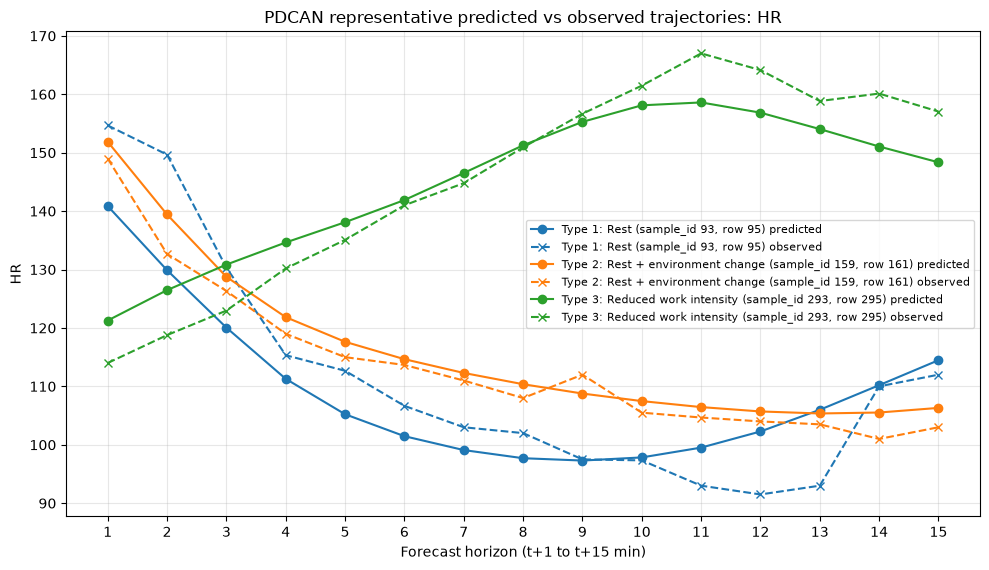

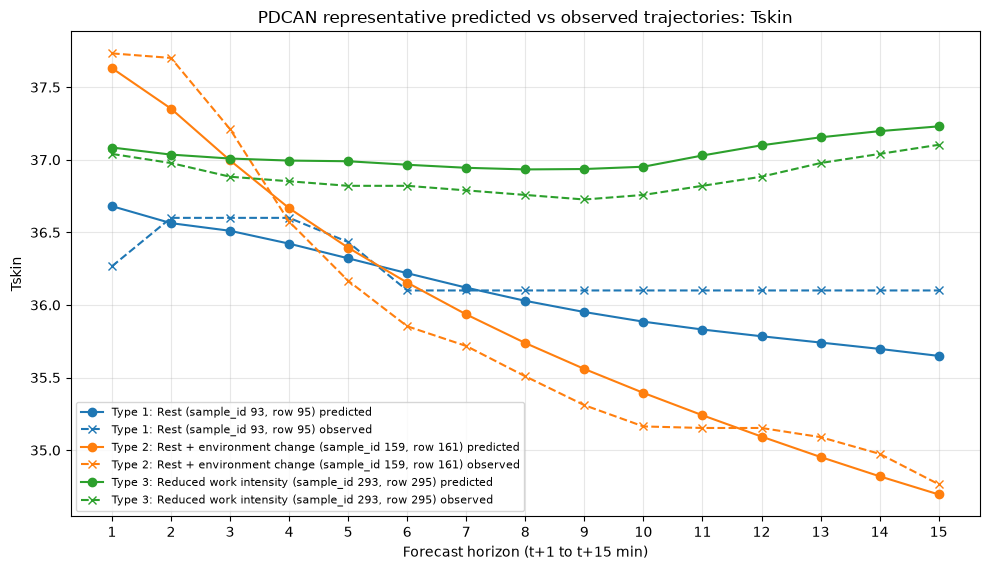

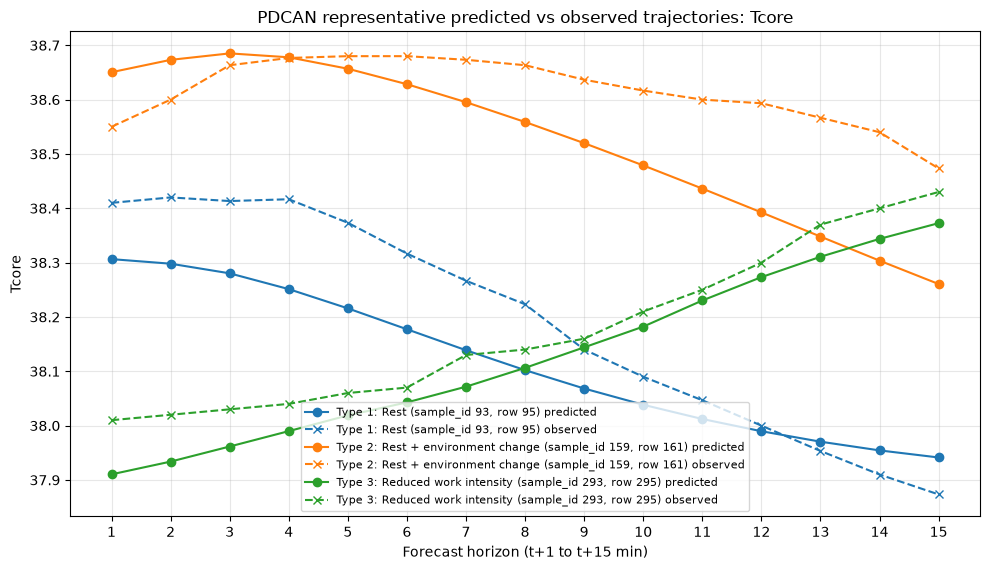

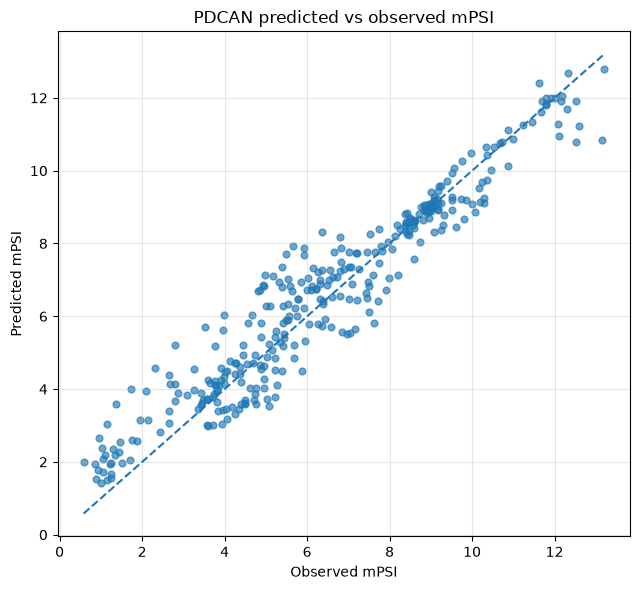

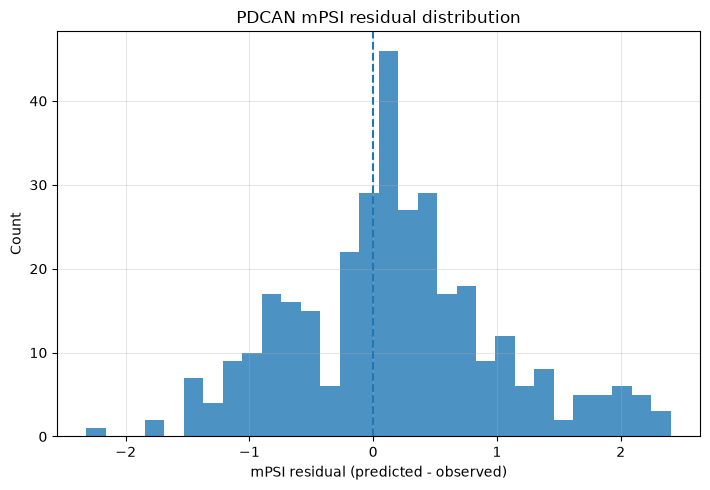


PDCAN 测试集 type=1/2/3 分类型结果：


,type,n_samples,MAE_HR,RMSE_HR,R2_HR,ME_HR,MAE_Tskin,RMSE_Tskin,R2_Tskin,ME_Tskin,MAE_Tcore,RMSE_Tcore,R2_Tcore,ME_Tcore,MAE_mPSI,RMSE_mPSI,R2_mPSI,ME_mPSI
0,1,96,7.595591,11.497499,0.845292,-0.045673,0.206156,0.287511,0.587195,0.048341,0.093215,0.128208,0.748374,-0.011102,0.817157,1.006555,0.688464,0.516774
1,2,144,3.935307,5.784077,0.960129,1.915792,0.172164,0.235028,0.954042,-0.064345,0.103685,0.138056,0.798389,-0.001742,0.578246,0.727681,0.921741,-0.165978
2,3,96,6.063563,8.584555,0.837252,1.685374,0.143461,0.183639,0.831847,-0.079429,0.053943,0.069012,0.935950,0.023091,0.603359,0.879167,0.772963,0.333854



PDCAN type=1/2/3 代表性样本：


,array_index,sample_id,source_row,type,MAE_HR,MAE_Tskin,MAE_Tcore,ME_HR,ME_Tskin,ME_Tcore,ABSERR_mPSI,ME_mPSI,score_MAE_HR,score_MAE_Tskin,score_MAE_Tcore,score_ABSERR_mPSI,representative_score
0,93.0,93.0,95.0,1.0,6.825948,0.213240,0.091174,-2.363880,-0.139622,-0.073905,0.652319,0.652319,0.010267,0.001181,0.000479,0.040692,0.052619
1,159.0,159.0,161.0,2.0,2.705255,0.181533,0.116063,2.275047,0.036582,-0.089836,0.512446,-0.512446,0.097699,0.002961,0.014253,0.012949,0.127862
2,293.0,293.0,295.0,3.0,5.086802,0.153766,0.048526,-0.645018,0.153766,-0.048526,0.790217,-0.790217,0.025949,0.005160,0.010083,0.095912,0.137103


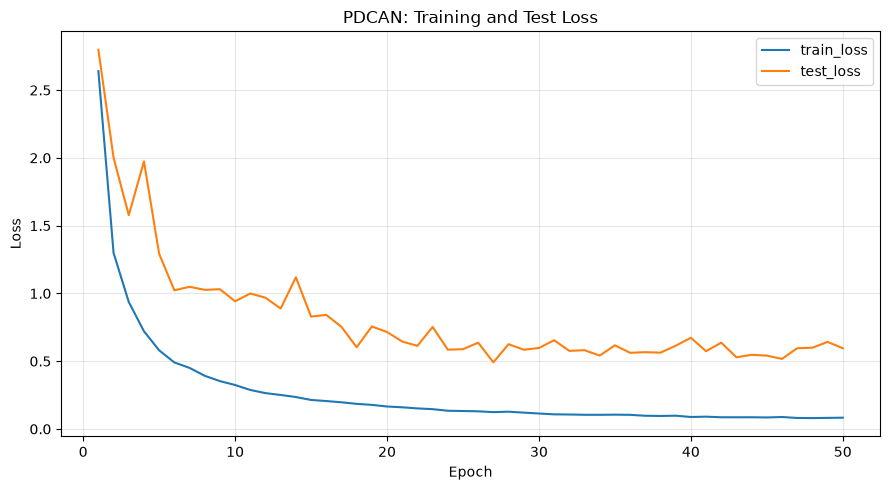

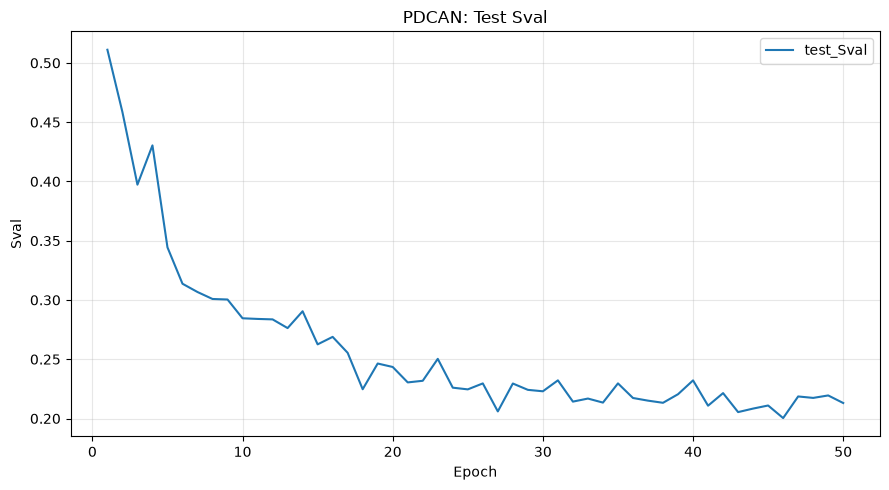

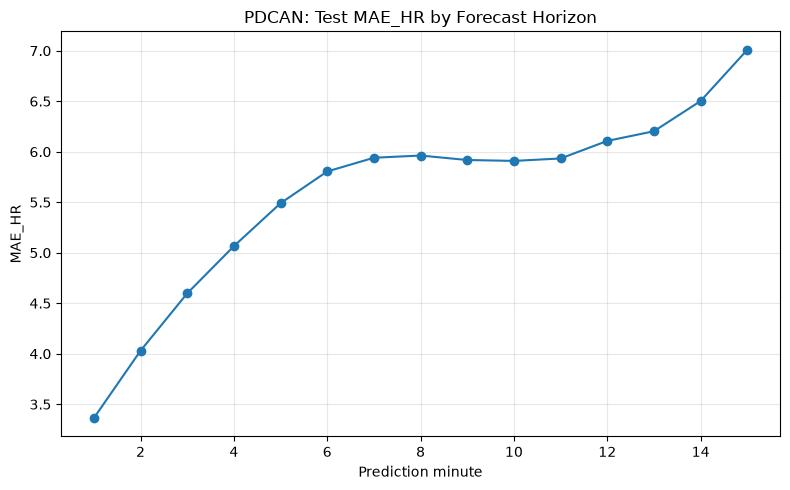

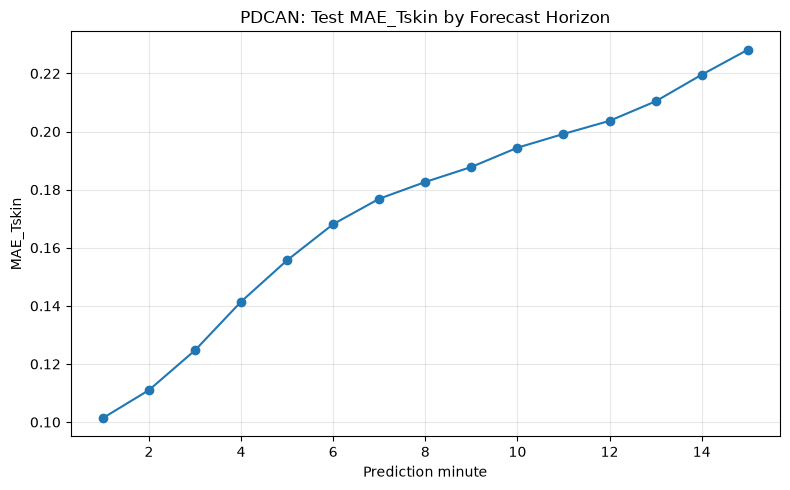

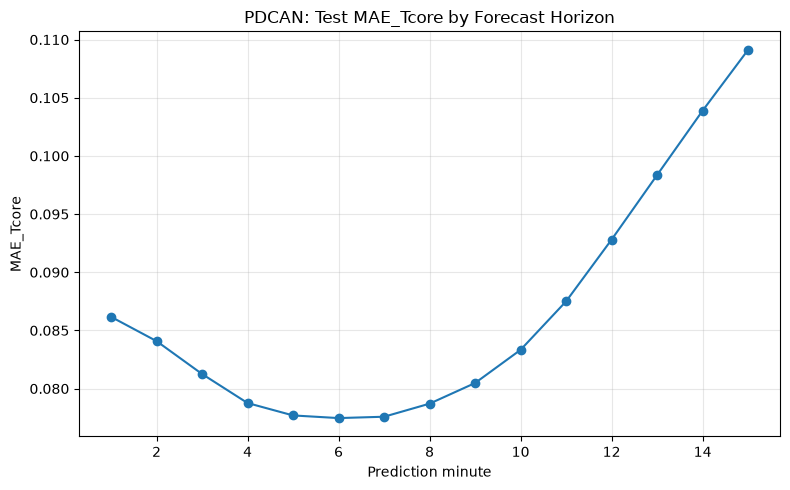


PDCAN 固定轮次最终测试结果：


,model,trained_epochs,test_loss,MAE_HR,RMSE_HR,R2_HR,ME_HR,MAE_Tskin,RMSE_Tskin,R2_Tskin,ME_Tskin,MAE_Tcore,RMSE_Tcore,R2_Tcore,ME_Tcore,MAE_mPSI,RMSE_mPSI,R2_mPSI,ME_mPSI,Sval
0,PDCAN,50,0.595647,5.589176,8.553535,0.911712,1.28954,0.173675,0.238593,0.941008,-0.036459,0.086481,0.119271,0.888884,0.002679,0.653682,0.858631,0.912283,0.171903,0.213078



开始训练消融模型：PDCAN_AR_feedback | PDCAN-AR
固定训练轮次：50
{
  "static_hidden": [
    64,
    64
  ],
  "tcn_channels": [
    64,
    64
  ],
  "tcn_kernel": 5,
  "history_gru_hidden_dims": [
    128,
    128
  ],
  "control_gru_hidden": 64,
  "decoder_hidden_dims": [
    64,
    128
  ],
  "dropout": 0.1,
  "activation": "silu",
  "lr": 0.001,
  "weight_decay": 1e-05,
  "batch_size": 128,
  "alpha_hr": 1.5,
  "alpha_tskin": 1.0,
  "alpha_tcore": 1.0,
  "lambda_phys": 1.0,
  "lambda_mpsi": 3.0,
  "lambda_smooth": 0.0001,
  "tf_start": 0.8,
  "tf_end": 0.05
}
PDCAN_AR_feedback | Epoch 001/050 | train_loss 1.6361 | test_loss 2.4254 | Sval 0.4787 | MAE_mPSI 1.4197 RMSE_mPSI 1.7323 R2_mPSI 0.6430 ME_mPSI -0.2478 | MAE_HR 11.1843 RMSE_HR 13.9871 R2_HR 0.7639 ME_HR -0.1582 | MAE_Tskin 0.4069 RMSE_Tskin 0.5264 R2_Tskin 0.7129 ME_Tskin -0.1081 | MAE_Tcore 0.2240 RMSE_Tcore 0.2960 R2_Tcore 0.3155 ME_Tcore -0.0353 | tf 0.800
PDCAN_AR_feedback | Epoch 002/050 | train_loss 0.2032 | test_loss 2.6002 | Sval 0

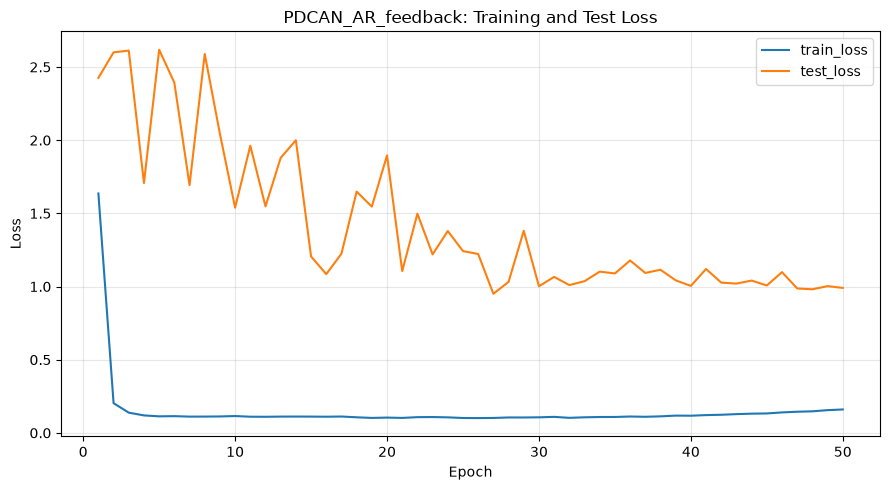

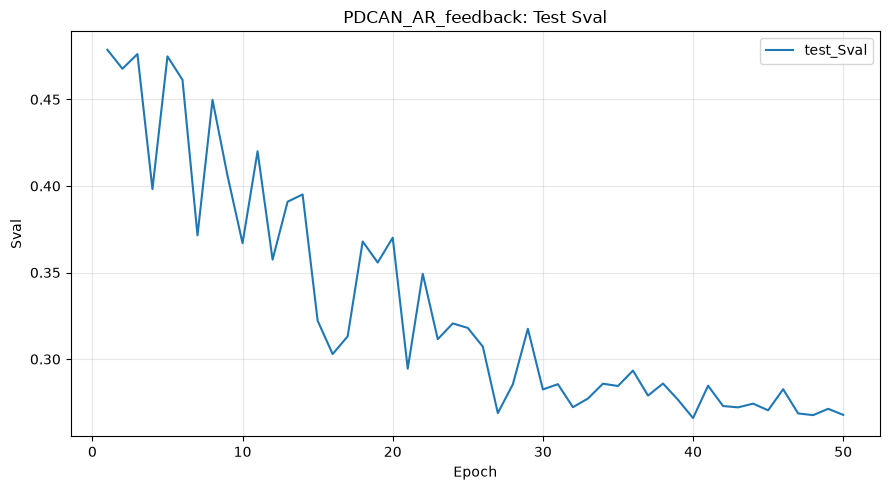

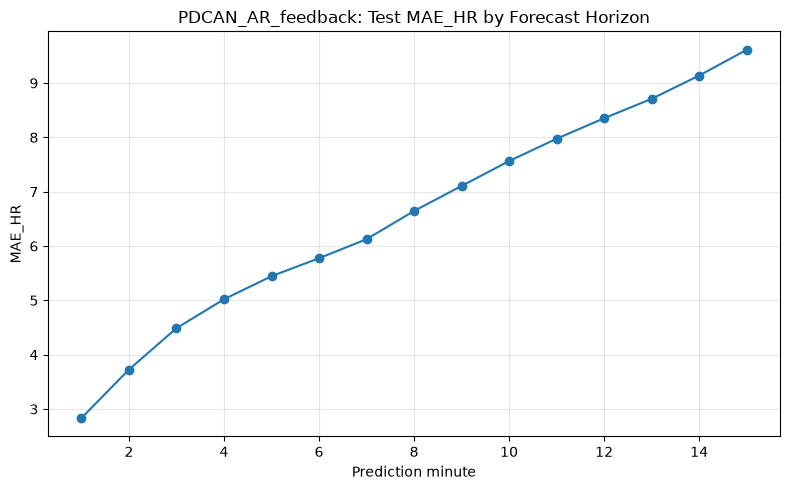

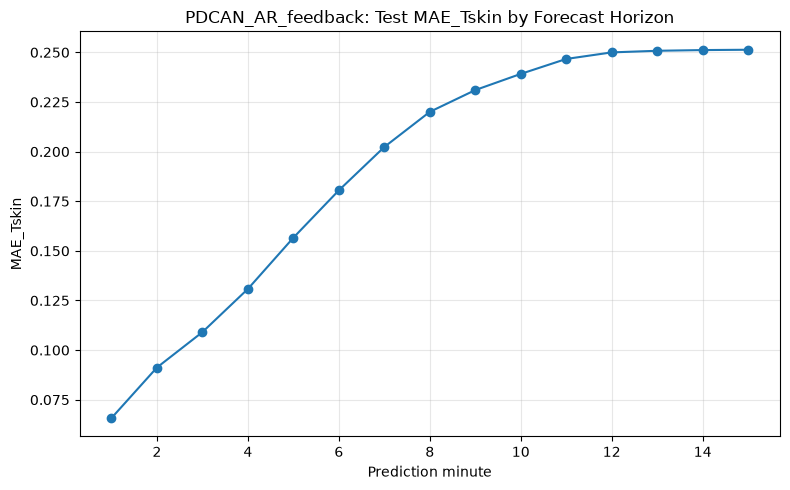

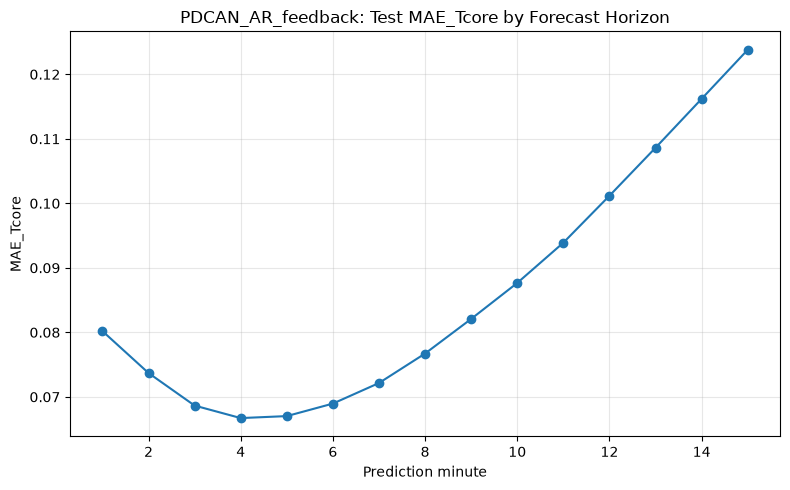


PDCAN_AR_feedback 固定轮次最终测试结果：


,model,trained_epochs,test_loss,MAE_HR,RMSE_HR,R2_HR,ME_HR,MAE_Tskin,RMSE_Tskin,R2_Tskin,ME_Tskin,MAE_Tcore,RMSE_Tcore,R2_Tcore,ME_Tcore,MAE_mPSI,RMSE_mPSI,R2_mPSI,ME_mPSI,Sval
0,PDCAN_AR_feedback,50,0.990869,6.567919,9.836203,0.883248,2.669994,0.191767,0.269184,0.924911,-0.012533,0.085837,0.116541,0.893912,-0.017784,0.950223,1.239147,0.81731,0.142919,0.267797



开始训练消融模型：PDCAN_no_future_context | PDCAN w/o future-control context
固定训练轮次：50
{
  "static_hidden": [
    64,
    64
  ],
  "tcn_channels": [
    64,
    64
  ],
  "tcn_kernel": 5,
  "history_gru_hidden_dims": [
    128,
    128
  ],
  "control_gru_hidden": 64,
  "decoder_hidden_dims": [
    64,
    128
  ],
  "dropout": 0.1,
  "activation": "silu",
  "lr": 0.001,
  "weight_decay": 1e-05,
  "batch_size": 128,
  "alpha_hr": 1.5,
  "alpha_tskin": 1.0,
  "alpha_tcore": 1.0,
  "lambda_phys": 1.0,
  "lambda_mpsi": 3.0,
  "lambda_smooth": 0.0001,
  "tf_start": 0.8,
  "tf_end": 0.05
}
PDCAN_no_future_context | Epoch 001/050 | train_loss 2.8337 | test_loss 2.4026 | Sval 0.4819 | MAE_mPSI 1.3812 RMSE_mPSI 1.6873 R2_mPSI 0.6613 ME_mPSI 0.1978 | MAE_HR 11.1321 RMSE_HR 13.9878 R2_HR 0.7639 ME_HR 0.8870 | MAE_Tskin 0.4006 RMSE_Tskin 0.5055 R2_Tskin 0.7352 ME_Tskin -0.1034 | MAE_Tcore 0.2453 RMSE_Tcore 0.3119 R2_Tcore 0.2400 ME_Tcore 0.0244 | tf 0.000
PDCAN_no_future_context | Epoch 002/050 | train_

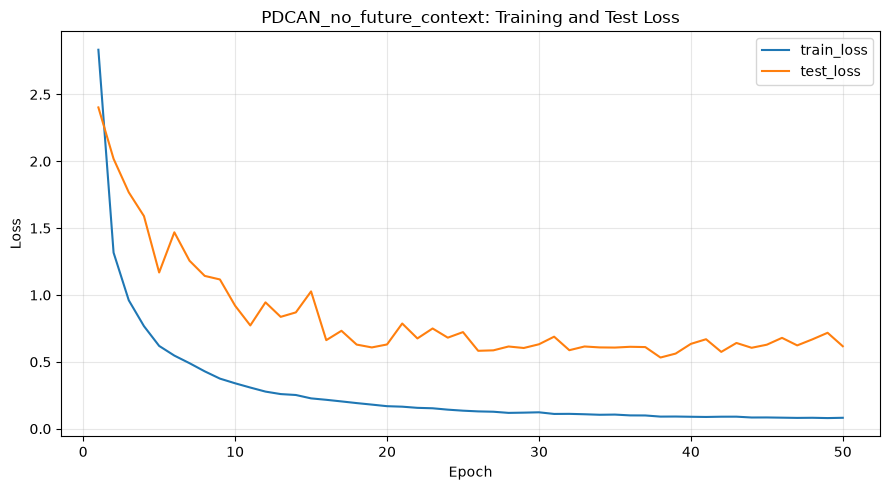

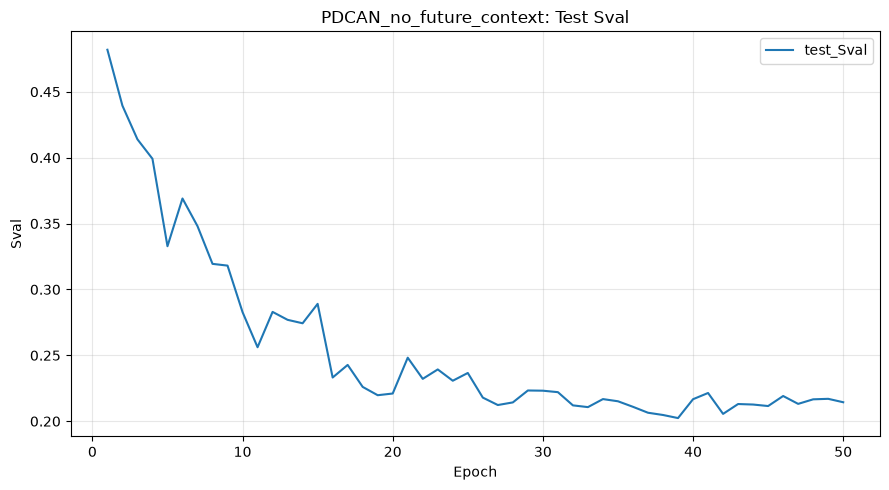

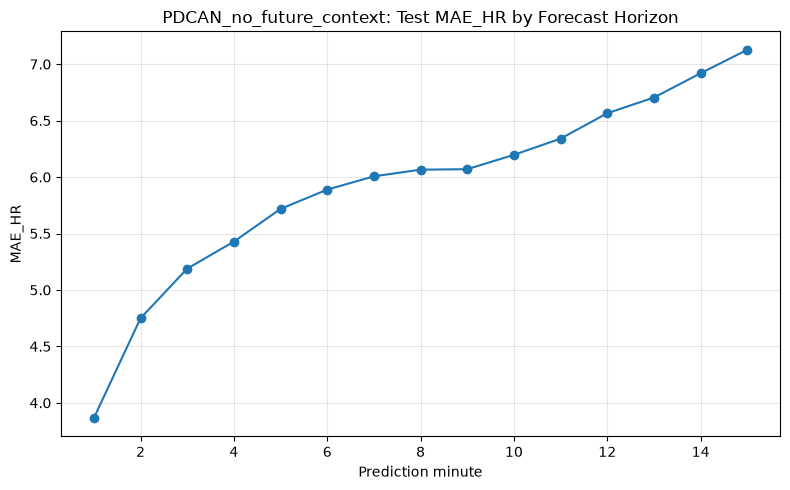

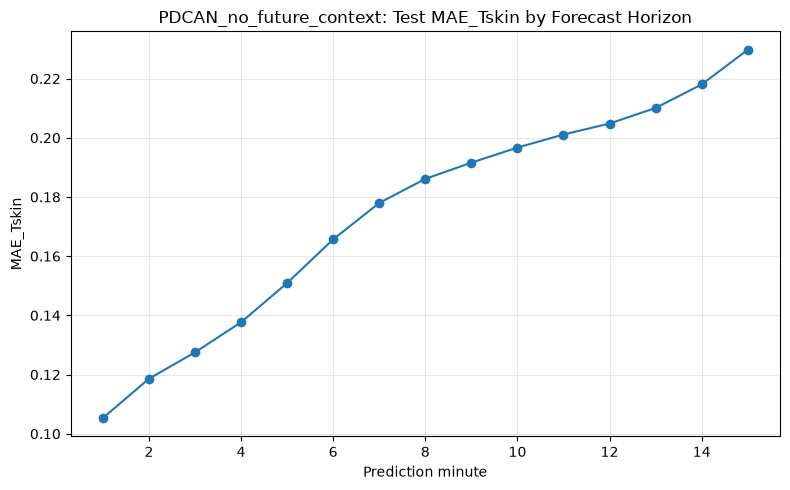

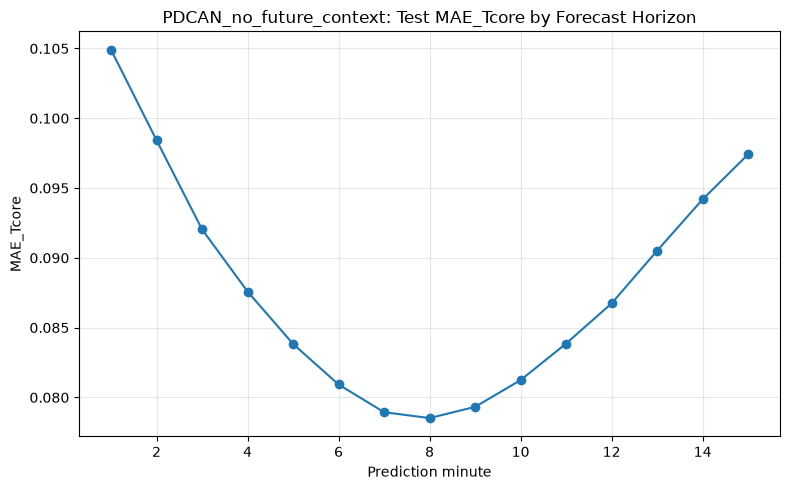


PDCAN_no_future_context 固定轮次最终测试结果：


,model,trained_epochs,test_loss,MAE_HR,RMSE_HR,R2_HR,ME_HR,MAE_Tskin,RMSE_Tskin,R2_Tskin,ME_Tskin,MAE_Tcore,RMSE_Tcore,R2_Tcore,ME_Tcore,MAE_mPSI,RMSE_mPSI,R2_mPSI,ME_mPSI,Sval
0,PDCAN_no_future_context,50,0.616825,5.922235,8.925699,0.903862,0.668667,0.174786,0.239914,0.940353,-0.060963,0.087897,0.118359,0.890577,-0.004405,0.640052,0.870048,0.909935,0.060104,0.214416



开始训练消融模型：PDCAN_no_smooth_loss | PDCAN w/o smoothness loss
固定训练轮次：50
{
  "static_hidden": [
    64,
    64
  ],
  "tcn_channels": [
    64,
    64
  ],
  "tcn_kernel": 5,
  "history_gru_hidden_dims": [
    128,
    128
  ],
  "control_gru_hidden": 64,
  "decoder_hidden_dims": [
    64,
    128
  ],
  "dropout": 0.1,
  "activation": "silu",
  "lr": 0.001,
  "weight_decay": 1e-05,
  "batch_size": 128,
  "alpha_hr": 1.5,
  "alpha_tskin": 1.0,
  "alpha_tcore": 1.0,
  "lambda_phys": 1.0,
  "lambda_mpsi": 3.0,
  "lambda_smooth": 0.0,
  "tf_start": 0.8,
  "tf_end": 0.05
}
PDCAN_no_smooth_loss | Epoch 001/050 | train_loss 2.6828 | test_loss 2.6623 | Sval 0.5142 | MAE_mPSI 1.4499 RMSE_mPSI 1.7494 R2_mPSI 0.6359 ME_mPSI 0.7006 | MAE_HR 10.6253 RMSE_HR 13.2620 R2_HR 0.7878 ME_HR 0.4561 | MAE_Tskin 0.4315 RMSE_Tskin 0.5226 R2_Tskin 0.7170 ME_Tskin -0.0154 | MAE_Tcore 0.2867 RMSE_Tcore 0.3603 R2_Tcore -0.0139 ME_Tcore 0.1334 | tf 0.000
PDCAN_no_smooth_loss | Epoch 002/050 | train_loss 1.2876 | test

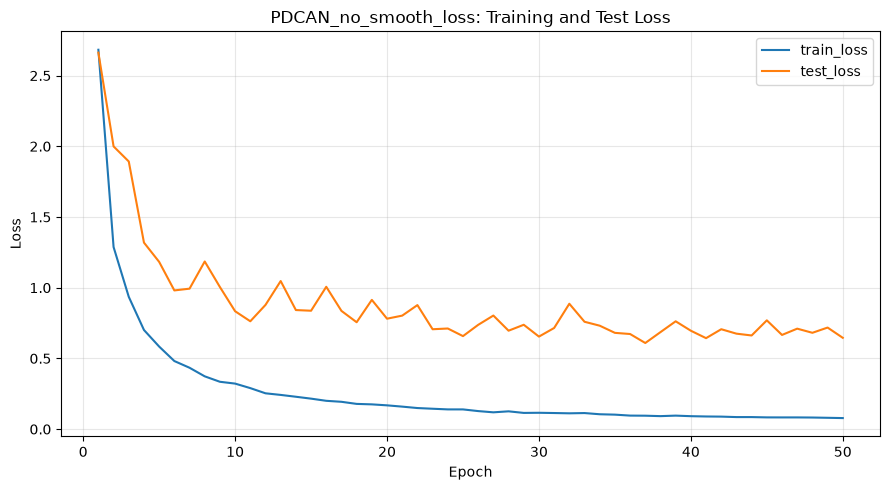

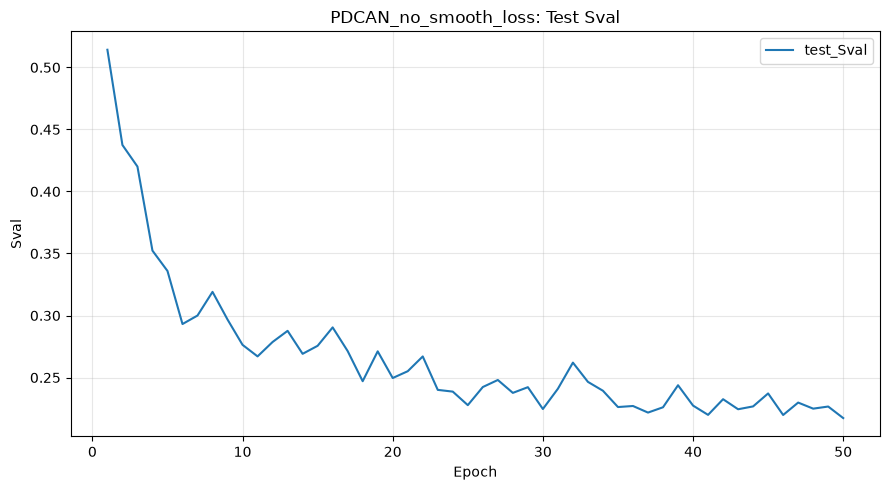

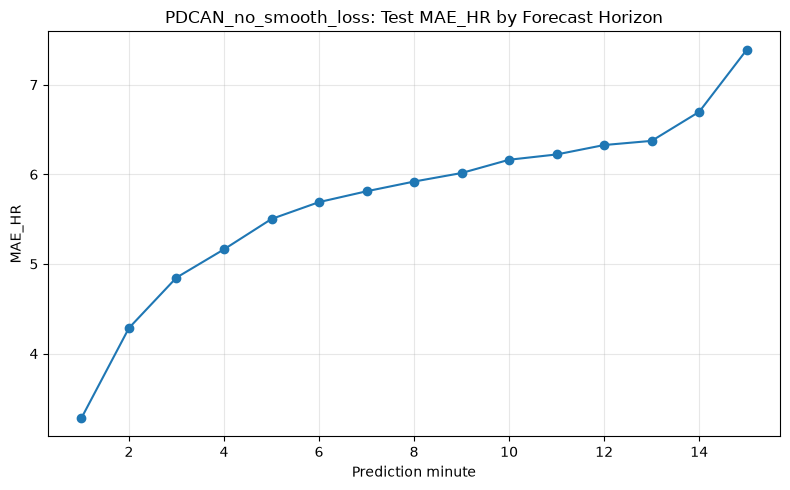

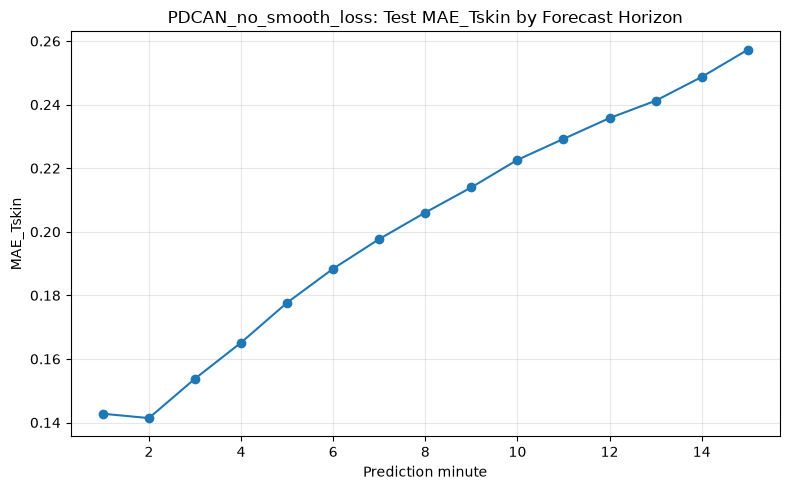

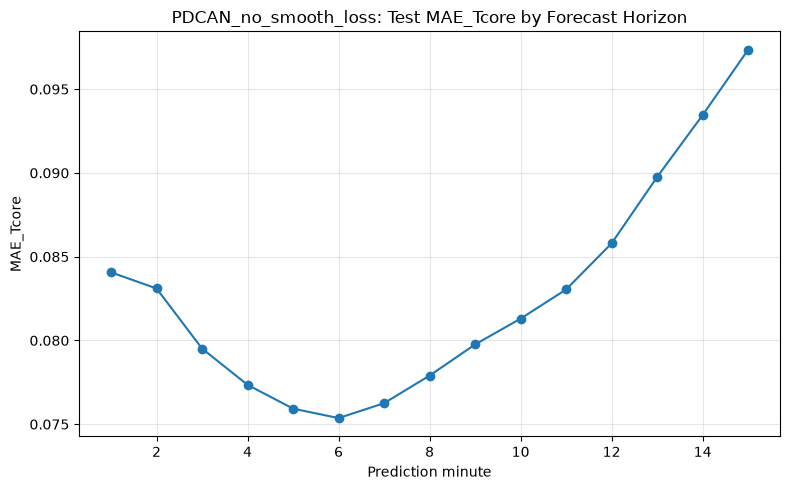


PDCAN_no_smooth_loss 固定轮次最终测试结果：


,model,trained_epochs,test_loss,MAE_HR,RMSE_HR,R2_HR,ME_HR,MAE_Tskin,RMSE_Tskin,R2_Tskin,ME_Tskin,MAE_Tcore,RMSE_Tcore,R2_Tcore,ME_Tcore,MAE_mPSI,RMSE_mPSI,R2_mPSI,ME_mPSI,Sval
0,PDCAN_no_smooth_loss,50,0.645734,5.712422,8.407041,0.91471,0.050842,0.20145,0.272707,0.922932,-0.077158,0.082663,0.107343,0.909997,-0.013369,0.655935,0.935497,0.895875,0.126,0.217324



开始训练消融模型：PDCAN_formula_mpsi_only | PDCAN w/o residual mPSI calibration
固定训练轮次：50
{
  "static_hidden": [
    64,
    64
  ],
  "tcn_channels": [
    64,
    64
  ],
  "tcn_kernel": 5,
  "history_gru_hidden_dims": [
    128,
    128
  ],
  "control_gru_hidden": 64,
  "decoder_hidden_dims": [
    64,
    128
  ],
  "dropout": 0.1,
  "activation": "silu",
  "lr": 0.001,
  "weight_decay": 1e-05,
  "batch_size": 128,
  "alpha_hr": 1.5,
  "alpha_tskin": 1.0,
  "alpha_tcore": 1.0,
  "lambda_phys": 1.0,
  "lambda_mpsi": 3.0,
  "lambda_smooth": 0.0001,
  "tf_start": 0.8,
  "tf_end": 0.05
}
PDCAN_formula_mpsi_only | Epoch 001/050 | train_loss 2.7130 | test_loss 2.4638 | Sval 0.4919 | MAE_mPSI 1.3852 RMSE_mPSI 1.7063 R2_mPSI 0.6536 ME_mPSI 0.2728 | MAE_HR 12.2389 RMSE_HR 14.7679 R2_HR 0.7368 ME_HR -1.8396 | MAE_Tskin 0.4100 RMSE_Tskin 0.5171 R2_Tskin 0.7229 ME_Tskin -0.1272 | MAE_Tcore 0.2443 RMSE_Tcore 0.3060 R2_Tcore 0.2687 ME_Tcore 0.0313 | tf 0.000
PDCAN_formula_mpsi_only | Epoch 002/050 | tr

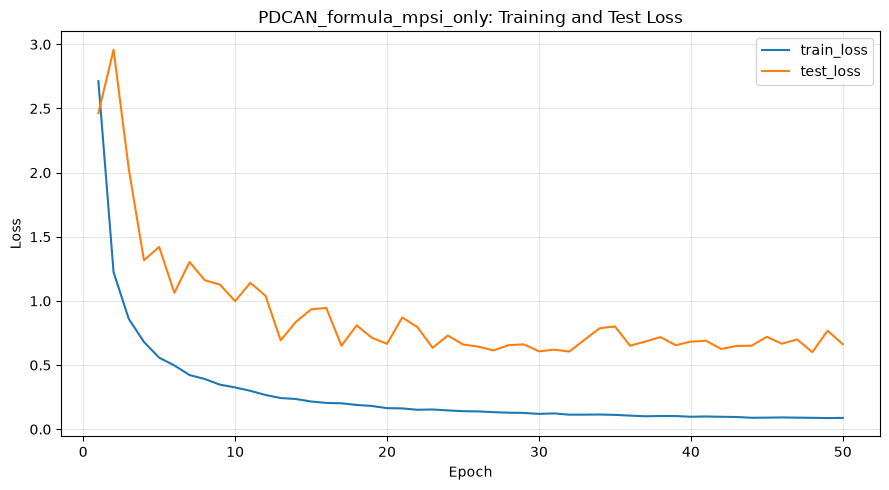

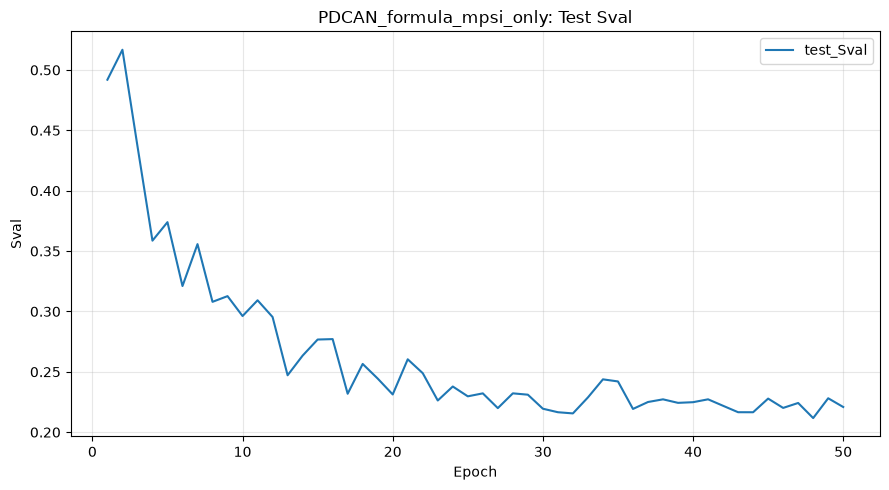

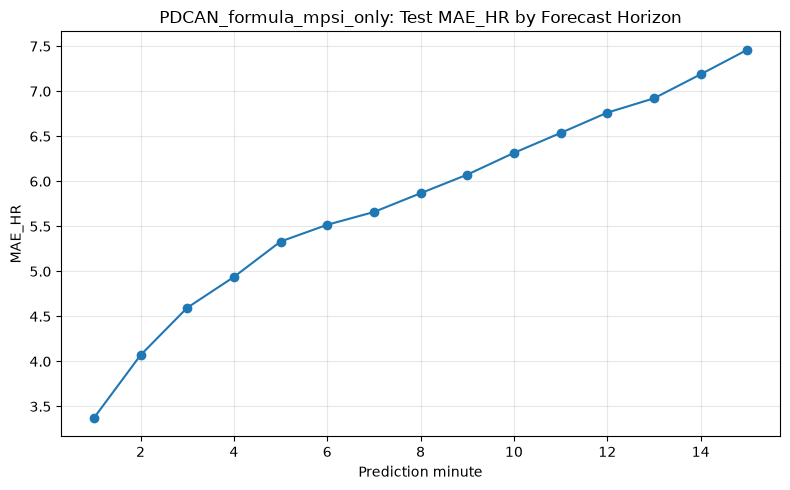

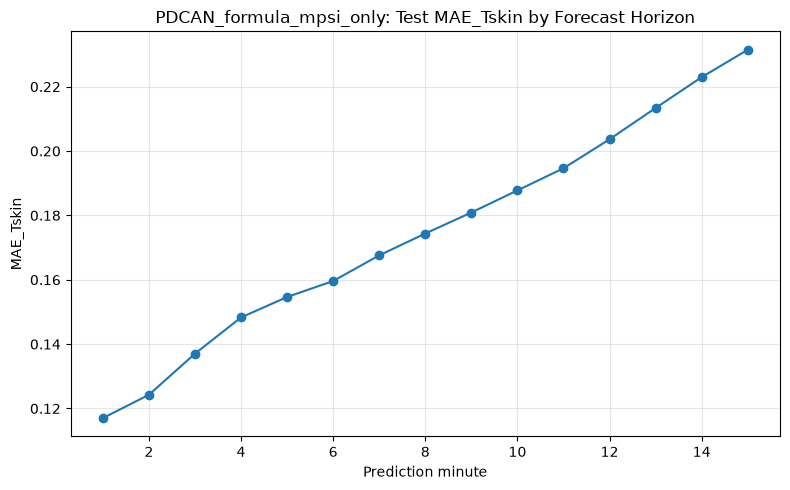

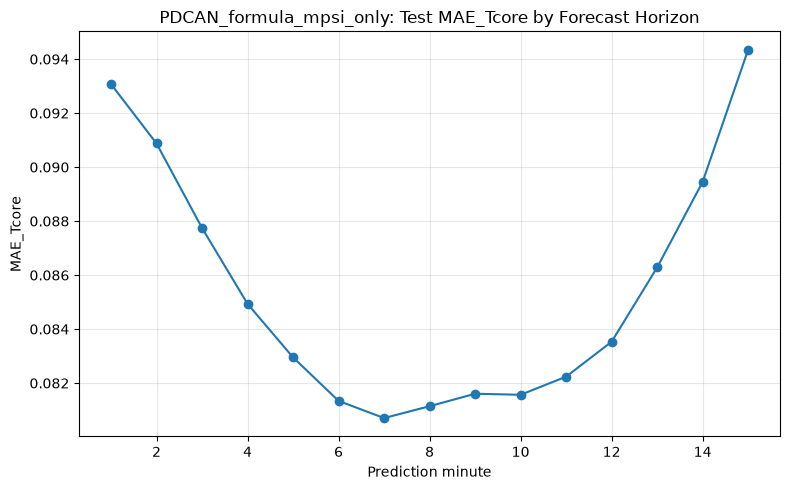


PDCAN_formula_mpsi_only 固定轮次最终测试结果：


,model,trained_epochs,test_loss,MAE_HR,RMSE_HR,R2_HR,ME_HR,MAE_Tskin,RMSE_Tskin,R2_Tskin,ME_Tskin,MAE_Tcore,RMSE_Tcore,R2_Tcore,ME_Tcore,MAE_mPSI,RMSE_mPSI,R2_mPSI,ME_mPSI,Sval
0,PDCAN_formula_mpsi_only,50,0.662662,5.773526,8.908416,0.904234,0.332861,0.174508,0.238658,0.940976,-0.08066,0.085453,0.119277,0.888872,0.022431,0.698707,0.92996,0.897104,0.009649,0.22086


All requested PDCAN ablation experiments finished.


In [10]:
# =========================
# 9. Train all PDCAN ablation variants
# =========================
models_to_run = ABLATION_ORDER if MODELS_TO_RUN is None else MODELS_TO_RUN
print("Models to run:", models_to_run)

ablation_results = {}
for model_name in models_to_run:
    if model_name not in ABLATION_CONFIGS:
        raise ValueError(f"Unknown ablation model: {model_name}")
    hp = copy.deepcopy(ABLATION_HYPERPARAMS[model_name])
    result = train_and_evaluate_model(
        model_name,
        hp,
        train_data,
        test_data,
        scalers,
        fixed_epochs=FIXED_ABLATION_EPOCHS,
    )
    ablation_results[model_name] = result

results = [ablation_results[name] for name in models_to_run]
print("All requested PDCAN ablation experiments finished.")


In [11]:
# =========================
# 10. Summarize PDCAN ablation results
# =========================
if "PDCAN" not in ablation_results:
    raise RuntimeError("PDCAN must be included in the run to compute deltas against the selected model.")

summary_df = pd.DataFrame([ablation_results[name]["summary_row"] for name in ABLATION_ORDER if name in ablation_results])
summary_df.insert(1, "ablation_label", [ABLATION_CONFIGS[name]["label"] for name in summary_df["model"]])
summary_df.insert(2, "paper_label", [ABLATION_CONFIGS[name]["paper_label"] for name in summary_df["model"]])
summary_df.insert(3, "description", [ABLATION_CONFIGS[name]["description"] for name in summary_df["model"]])
summary_path = os.path.join(OUTPUT_DIR, "PDCAN_ablation_final_metrics_summary.csv")
summary_df.to_csv(summary_path, index=False, encoding="utf-8-sig")
display(summary_df)
print("Saved:", summary_path)

metric_cols = [
    "Sval",
    "MAE_HR", "RMSE_HR", "R2_HR", "ME_HR",
    "MAE_Tskin", "RMSE_Tskin", "R2_Tskin", "ME_Tskin",
    "MAE_Tcore", "RMSE_Tcore", "R2_Tcore", "ME_Tcore",
    "MAE_mPSI", "RMSE_mPSI", "R2_mPSI", "ME_mPSI",
]
baseline = summary_df.loc[summary_df["model"] == "PDCAN"].iloc[0]
delta_rows = []
for _, row in summary_df.iterrows():
    delta = {
        "model": row["model"],
        "ablation_label": row["ablation_label"],
        "paper_label": row["paper_label"],
        "description": row["description"],
    }
    for col in metric_cols:
        if col in row and col in baseline:
            if col.startswith("R2_"):
                # For R2, negative delta means worse than PDCAN.
                delta[f"delta_{col}_vs_PDCAN"] = row[col] - baseline[col]
            else:
                # For errors and Sval, positive delta means worse than PDCAN.
                delta[f"delta_{col}_vs_PDCAN"] = row[col] - baseline[col]
    delta_rows.append(delta)

delta_df = pd.DataFrame(delta_rows)
delta_path = os.path.join(OUTPUT_DIR, "PDCAN_ablation_delta_vs_PDCAN.csv")
delta_df.to_csv(delta_path, index=False, encoding="utf-8-sig")
display(delta_df)
print("Saved:", delta_path)

paper_cols = [
    "model", "paper_label",
    "MAE_HR", "RMSE_HR", "R2_HR",
    "MAE_Tskin", "RMSE_Tskin", "R2_Tskin",
    "MAE_Tcore", "RMSE_Tcore", "R2_Tcore",
    "MAE_mPSI", "RMSE_mPSI", "R2_mPSI", "ME_mPSI", "Sval",
]
paper_summary_df = summary_df[[c for c in paper_cols if c in summary_df.columns]].copy()
paper_summary_path = os.path.join(OUTPUT_DIR, "PDCAN_ablation_paper_table.csv")
paper_summary_df.to_csv(paper_summary_path, index=False, encoding="utf-8-sig")
display(paper_summary_df)
print("Saved:", paper_summary_path)


,model,ablation_label,paper_label,description,trained_epochs,test_loss,MAE_HR,RMSE_HR,R2_HR,ME_HR,...,ME_Tskin,MAE_Tcore,RMSE_Tcore,R2_Tcore,ME_Tcore,MAE_mPSI,RMSE_mPSI,R2_mPSI,ME_mPSI,Sval
0,PDCAN,PDCAN,Full PDCAN,Selected Physiology-Driven Control Aware Netwo...,50,0.595647,5.589176,8.553535,0.911712,1.289540,...,-0.036459,0.086481,0.119271,0.888884,0.002679,0.653682,0.858631,0.912283,0.171903,0.213078
1,PDCAN_AR_feedback,PDCAN-AR,with autoregressive physiological feedback,Adds explicit feedback of the previous predict...,50,0.990869,6.567919,9.836203,0.883248,2.669994,...,-0.012533,0.085837,0.116541,0.893912,-0.017784,0.950223,1.239147,0.817310,0.142919,0.267797
2,PDCAN_no_future_context,PDCAN w/o future-control context,w/o future-control context encoder,Removes the encoder-level global future-contro...,50,0.616825,5.922235,8.925699,0.903862,0.668667,...,-0.060963,0.087897,0.118359,0.890577,-0.004405,0.640052,0.870048,0.909935,0.060104,0.214416
3,PDCAN_no_smooth_loss,PDCAN w/o smoothness loss,w/o trajectory smoothness loss,Keeps the selected PDCAN architecture but remo...,50,0.645734,5.712422,8.407041,0.914710,0.050842,...,-0.077158,0.082663,0.107343,0.909997,-0.013369,0.655935,0.935497,0.895875,0.126000,0.217324
4,PDCAN_formula_mpsi_only,PDCAN w/o residual mPSI calibration,w/o residual mPSI calibration head,Keeps the selected PDCAN trajectory decoder bu...,50,0.662662,5.773526,8.908416,0.904234,0.332861,...,-0.080660,0.085453,0.119277,0.888872,0.022431,0.698707,0.929960,0.897104,0.009649,0.220860


Saved: ./PDCAN_ablation_fixed_epoch_outputs/PDCAN_ablation_final_metrics_summary.csv


,model,ablation_label,paper_label,description,delta_Sval_vs_PDCAN,delta_MAE_HR_vs_PDCAN,delta_RMSE_HR_vs_PDCAN,delta_R2_HR_vs_PDCAN,delta_ME_HR_vs_PDCAN,delta_MAE_Tskin_vs_PDCAN,...,delta_R2_Tskin_vs_PDCAN,delta_ME_Tskin_vs_PDCAN,delta_MAE_Tcore_vs_PDCAN,delta_RMSE_Tcore_vs_PDCAN,delta_R2_Tcore_vs_PDCAN,delta_ME_Tcore_vs_PDCAN,delta_MAE_mPSI_vs_PDCAN,delta_RMSE_mPSI_vs_PDCAN,delta_R2_mPSI_vs_PDCAN,delta_ME_mPSI_vs_PDCAN
0,PDCAN,PDCAN,Full PDCAN,Selected Physiology-Driven Control Aware Netwo...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,PDCAN_AR_feedback,PDCAN-AR,with autoregressive physiological feedback,Adds explicit feedback of the previous predict...,0.054718,0.978744,1.282667,-0.028464,1.380454,0.018091,...,-0.016097,0.023926,-0.000645,-0.002729,0.005027,-0.020463,0.296541,0.380516,-0.094973,-0.028984
2,PDCAN_no_future_context,PDCAN w/o future-control context,w/o future-control context encoder,Removes the encoder-level global future-contro...,0.001338,0.333059,0.372164,-0.007850,-0.620873,0.001111,...,-0.000655,-0.024504,0.001416,-0.000912,0.001693,-0.007085,-0.013629,0.011417,-0.002348,-0.111799
3,PDCAN_no_smooth_loss,PDCAN w/o smoothness loss,w/o trajectory smoothness loss,Keeps the selected PDCAN architecture but remo...,0.004245,0.123246,-0.146495,0.002998,-1.238698,0.027775,...,-0.018076,-0.040699,-0.003819,-0.011928,0.021113,-0.016048,0.002253,0.076866,-0.016408,-0.045903
4,PDCAN_formula_mpsi_only,PDCAN w/o residual mPSI calibration,w/o residual mPSI calibration head,Keeps the selected PDCAN trajectory decoder bu...,0.007782,0.184350,0.354880,-0.007478,-0.956679,0.000833,...,-0.000032,-0.044201,-0.001028,0.000007,-0.000012,0.019752,0.045026,0.071329,-0.015179,-0.162254


Saved: ./PDCAN_ablation_fixed_epoch_outputs/PDCAN_ablation_delta_vs_PDCAN.csv


,model,paper_label,MAE_HR,RMSE_HR,R2_HR,MAE_Tskin,RMSE_Tskin,R2_Tskin,MAE_Tcore,RMSE_Tcore,R2_Tcore,MAE_mPSI,RMSE_mPSI,R2_mPSI,ME_mPSI,Sval
0,PDCAN,Full PDCAN,5.589176,8.553535,0.911712,0.173675,0.238593,0.941008,0.086481,0.119271,0.888884,0.653682,0.858631,0.912283,0.171903,0.213078
1,PDCAN_AR_feedback,with autoregressive physiological feedback,6.567919,9.836203,0.883248,0.191767,0.269184,0.924911,0.085837,0.116541,0.893912,0.950223,1.239147,0.817310,0.142919,0.267797
2,PDCAN_no_future_context,w/o future-control context encoder,5.922235,8.925699,0.903862,0.174786,0.239914,0.940353,0.087897,0.118359,0.890577,0.640052,0.870048,0.909935,0.060104,0.214416
3,PDCAN_no_smooth_loss,w/o trajectory smoothness loss,5.712422,8.407041,0.914710,0.201450,0.272707,0.922932,0.082663,0.107343,0.909997,0.655935,0.935497,0.895875,0.126000,0.217324
4,PDCAN_formula_mpsi_only,w/o residual mPSI calibration head,5.773526,8.908416,0.904234,0.174508,0.238658,0.940976,0.085453,0.119277,0.888872,0.698707,0.929960,0.897104,0.009649,0.220860


Saved: ./PDCAN_ablation_fixed_epoch_outputs/PDCAN_ablation_paper_table.csv


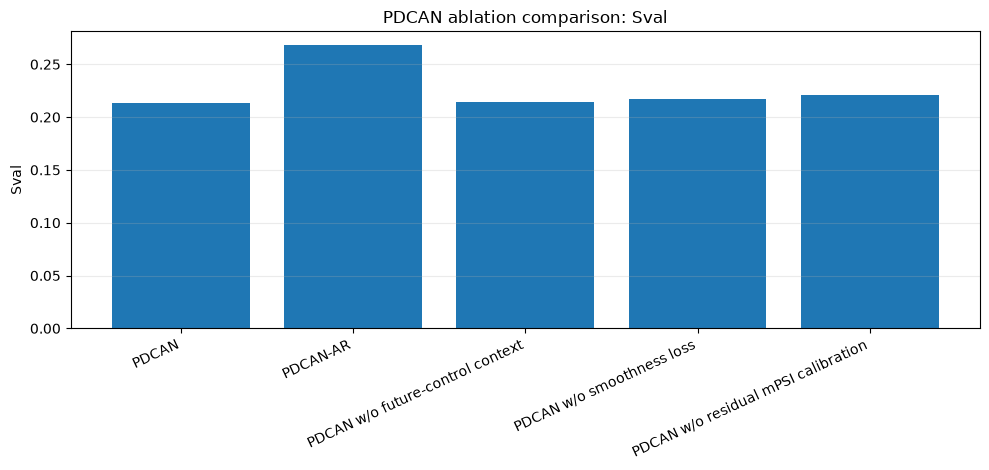

Saved: ./PDCAN_ablation_fixed_epoch_outputs/PDCAN_ablation_Sval.png


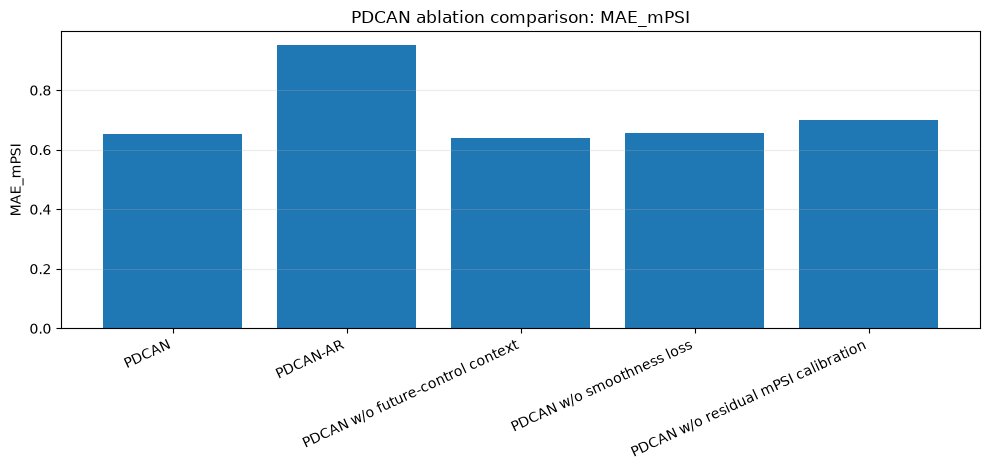

Saved: ./PDCAN_ablation_fixed_epoch_outputs/PDCAN_ablation_MAE_mPSI.png


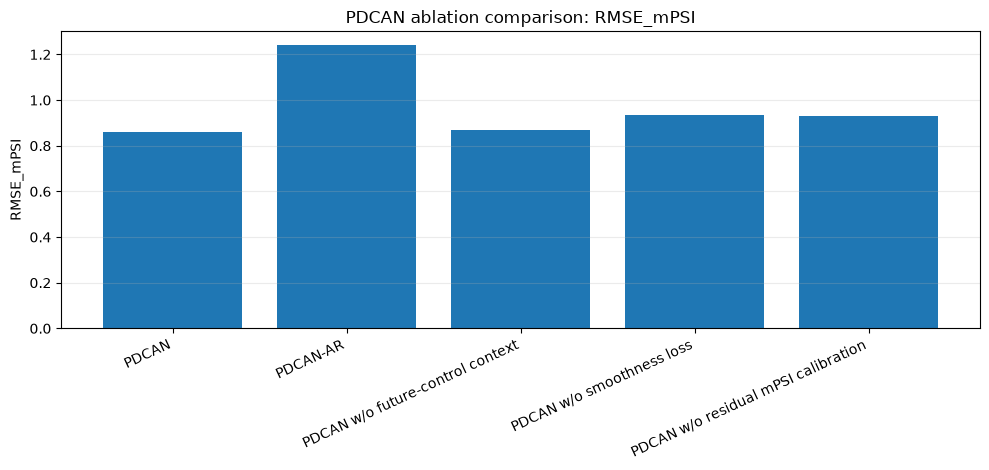

Saved: ./PDCAN_ablation_fixed_epoch_outputs/PDCAN_ablation_RMSE_mPSI.png


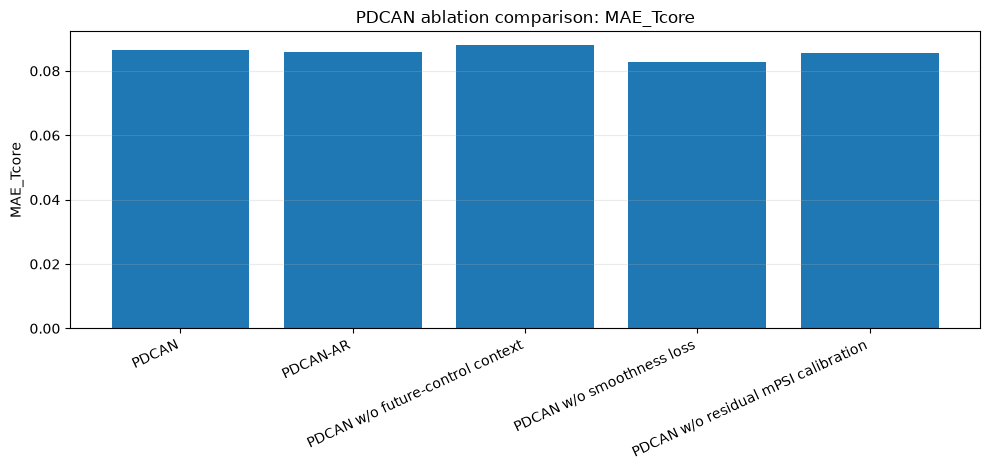

Saved: ./PDCAN_ablation_fixed_epoch_outputs/PDCAN_ablation_MAE_Tcore.png


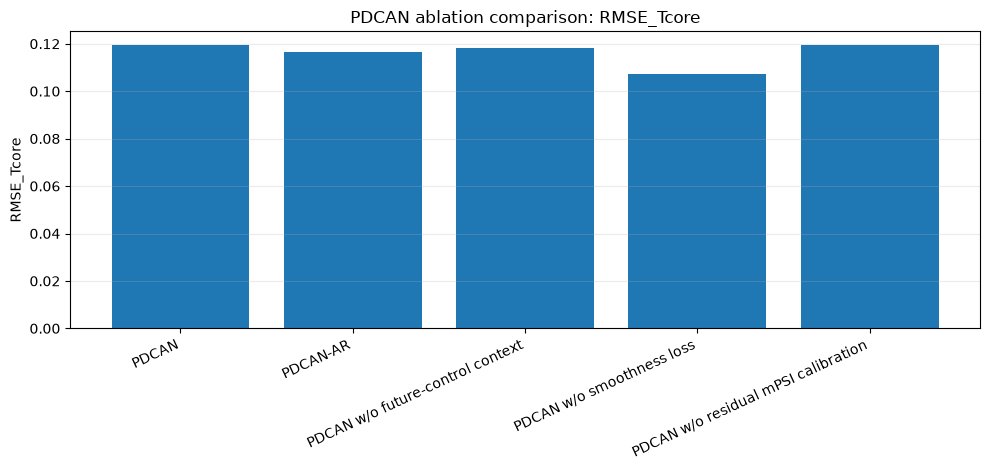

Saved: ./PDCAN_ablation_fixed_epoch_outputs/PDCAN_ablation_RMSE_Tcore.png


In [12]:
# =========================
# 11. Plot ablation comparison
# =========================
def plot_ablation_metric(summary_df: pd.DataFrame, metric: str, ylabel: str = None):
    df = summary_df.copy()
    df["label_for_plot"] = df["ablation_label"]
    plt.figure(figsize=(10, 4.8))
    plt.bar(df["label_for_plot"], df[metric])
    plt.ylabel(ylabel or metric)
    plt.xticks(rotation=25, ha="right")
    plt.title(f"PDCAN ablation comparison: {metric}")
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    path = os.path.join(OUTPUT_DIR, f"PDCAN_ablation_{metric}.png")
    plt.savefig(path, dpi=200)
    plt.show()
    print("Saved:", path)


for metric in ["Sval", "MAE_mPSI", "RMSE_mPSI", "MAE_Tcore", "RMSE_Tcore"]:
    if metric in summary_df.columns:
        plot_ablation_metric(summary_df, metric)


In [13]:
# =========================
# 12. Summarize ablation results by intervention type
# =========================
def compute_type_metrics_from_saved_predictions(model_name: str) -> pd.DataFrame:
    model_dir = os.path.join(OUTPUT_DIR, model_name)
    traj_path = os.path.join(model_dir, "test_predictions_trajectory.csv")
    mpsi_path = os.path.join(model_dir, "test_predictions_mpsi.csv")
    if not (os.path.exists(traj_path) and os.path.exists(mpsi_path)):
        print(f"{model_name}: prediction files are missing, skip type-wise summary.")
        return pd.DataFrame()

    traj_df = pd.read_csv(traj_path)
    mpsi_df = pd.read_csv(mpsi_path)
    rows = []
    for type_id in [1, 2, 3]:
        traj_sub = traj_df[np.isfinite(traj_df["type"]) & (traj_df["type"].astype(float) == float(type_id))]
        mpsi_sub = mpsi_df[np.isfinite(mpsi_df["type"]) & (mpsi_df["type"].astype(float) == float(type_id))]
        if traj_sub.empty or mpsi_sub.empty:
            continue
        row = {
            "model": model_name,
            "ablation_label": ABLATION_CONFIGS[model_name]["label"],
            "paper_label": ABLATION_CONFIGS[model_name]["paper_label"],
            "type": type_id,
            "n_samples": int(mpsi_sub["sample_id"].nunique()),
        }
        for var in ["HR", "Tskin", "Tcore"]:
            mae, rmse, r2, me = mae_rmse_r2_me(traj_sub[f"{var}_true"], traj_sub[f"{var}_pred"])
            row[f"MAE_{var}"] = mae
            row[f"RMSE_{var}"] = rmse
            row[f"R2_{var}"] = r2
            row[f"ME_{var}"] = me
        mae, rmse, r2, me = mae_rmse_r2_me(mpsi_sub["mPSI_true"], mpsi_sub["mPSI_pred"])
        row["MAE_mPSI"] = mae
        row["RMSE_mPSI"] = rmse
        row["R2_mPSI"] = r2
        row["ME_mPSI"] = me
        rows.append(row)
    return pd.DataFrame(rows)


type_summary_df = pd.concat(
    [compute_type_metrics_from_saved_predictions(name) for name in ABLATION_ORDER if name in ablation_results],
    ignore_index=True,
)
type_summary_path = os.path.join(OUTPUT_DIR, "PDCAN_ablation_type_metrics_summary.csv")
type_summary_df.to_csv(type_summary_path, index=False, encoding="utf-8-sig")
display(type_summary_df)
print("Saved:", type_summary_path)


,model,ablation_label,paper_label,type,n_samples,MAE_HR,RMSE_HR,R2_HR,ME_HR,MAE_Tskin,...,R2_Tskin,ME_Tskin,MAE_Tcore,RMSE_Tcore,R2_Tcore,ME_Tcore,MAE_mPSI,RMSE_mPSI,R2_mPSI,ME_mPSI
0,PDCAN,PDCAN,Full PDCAN,1,96,7.595591,11.497499,0.845293,-0.045673,0.206156,...,0.587195,0.048341,0.093215,0.128208,0.748373,-0.011102,0.817157,1.006555,0.688464,0.516774
1,PDCAN,PDCAN,Full PDCAN,2,144,3.935308,5.784077,0.960129,1.915792,0.172164,...,0.954042,-0.064345,0.103685,0.138056,0.798389,-0.001742,0.578246,0.727681,0.921741,-0.165978
2,PDCAN,PDCAN,Full PDCAN,3,96,6.063563,8.584554,0.837252,1.685374,0.143461,...,0.831846,-0.079429,0.053943,0.069012,0.935950,0.023091,0.603359,0.879167,0.772963,0.333854
3,PDCAN_AR_feedback,PDCAN-AR,with autoregressive physiological feedback,1,96,9.101710,11.874565,0.834979,5.703523,0.184188,...,0.680879,0.078539,0.064331,0.089538,0.877273,0.011307,1.021583,1.258574,0.512931,0.951361
4,PDCAN_AR_feedback,PDCAN-AR,with autoregressive physiological feedback,2,144,4.216776,5.726547,0.960918,-0.002959,0.227086,...,0.917206,-0.089506,0.101652,0.134589,0.808389,-0.049037,0.837992,1.107417,0.818752,-0.513330
5,PDCAN_AR_feedback,PDCAN-AR,with autoregressive physiological feedback,3,96,7.560841,12.183300,0.672200,3.645896,0.146366,...,0.798371,0.011854,0.083620,0.111122,0.833936,0.000005,1.047207,1.396651,0.427034,0.318852
6,PDCAN_no_future_context,PDCAN w/o future-control context,w/o future-control context encoder,1,96,7.237428,11.091527,0.856025,-0.002622,0.169801,...,0.751492,-0.026752,0.083856,0.128520,0.747151,-0.048017,0.665305,0.918814,0.740410,0.237506
7,PDCAN_no_future_context,PDCAN w/o future-control context,w/o future-control context encoder,2,144,4.511006,5.871994,0.958908,-0.775206,0.194063,...,0.936833,-0.070843,0.103792,0.128336,0.825778,0.013281,0.522700,0.650474,0.937467,-0.197986
8,PDCAN_no_future_context,PDCAN w/o future-control context,w/o future-control context encoder,3,96,6.723884,10.202742,0.770114,3.505765,0.150855,...,0.811470,-0.080355,0.068097,0.088364,0.894990,0.012676,0.790828,1.081920,0.656171,0.269836
9,PDCAN_no_smooth_loss,PDCAN w/o smoothness loss,w/o trajectory smoothness loss,1,96,6.913997,10.135739,0.879769,0.409542,0.188607,...,0.631667,0.001356,0.067371,0.090129,0.875647,-0.034552,0.673514,0.955009,0.719555,0.607566


Saved: ./PDCAN_ablation_fixed_epoch_outputs/PDCAN_ablation_type_metrics_summary.csv


## Ablation design

This notebook is different from the previous `pcan_ablation_fixed_epoch_experiments.ipynb`.

The previous notebook used the old Full PCAN with cascaded autoregressive physiological feedback as the reference model. This notebook uses the selected PDCAN as the reference model. Therefore, all non-AR component ablations keep `use_autoregressive_feedback=False`.

Variants:

1. `PDCAN`: selected model, no explicit predicted-output physiological feedback.
2. `PDCAN_AR_feedback`: adds explicit predicted-output physiological feedback, used as a sensitivity variant.
3. `PDCAN_no_future_context`: removes encoder-level global future-control context, while retaining minute-level future controls in the decoder.
4. `PDCAN_no_smooth_loss`: removes the second-order trajectory smoothness loss.
5. `PDCAN_formula_mpsi_only`: removes the learned residual mPSI calibration head.

Use `PDCAN_ablation_final_metrics_summary.csv` and `PDCAN_ablation_delta_vs_PDCAN.csv` for manuscript tables and interpretation.
